# System Configuration

In [1]:
# Memory info
!free -h

               total        used        free      shared  buff/cache   available
Mem:            31Gi       1.2Gi        19Gi       2.0Mi        10Gi        29Gi
Swap:             0B          0B          0B


In [2]:
# GPU info (if GPU is enabled in Settings > Accelerator)
!nvidia-smi

Thu May 29 16:07:23 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.03              Driver Version: 560.35.03      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       1MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:

# Disk usage
!df -h

Filesystem                                                              Size  Used Avail Use% Mounted on
overlay                                                                 7.9T  6.3T  1.7T  79% /
tmpfs                                                                    64M     0   64M   0% /dev
shm                                                                      14G     0   14G   0% /dev/shm
/dev/sdb1                                                               122G  6.1G  116G   5% /opt/bin
/dev/loop1                                                               20G  1.5G   19G   8% /kaggle/lib
192.168.5.2:/data/kagglesdsdata/datasets/6424373/10371517/da7v3t7rboks   68T   50T   18T  75% /kaggle/input/classification-taco
192.168.5.2:/data/kagglesdsdata/models/81059/96643/da7v3t7rezzo          68T   50T   18T  75% /kaggle/input/densennet121/pytorch/default/1
192.168.5.2:/data/kagglesdsdata/datasets/5558111/9193998/da7v3t7rj2n4    68T   50T   18T  75% /kaggle/input/trash-net-ori

In [4]:
# List all devices
!lsblk

NAME MAJ:MIN RM   SIZE RO TYPE MOUNTPOINTS
loop0
       7:0    0    96G  0 loop 
loop1
       7:1    0    20G  0 loop /etc/secrets/kaggle
                               /kaggle/working
                               /kaggle/input
                               /kaggle/lib
sda    8:0    0     8T  1 disk 
sdb    8:16   0   128G  0 disk 
├─sdb1
│      8:17   0 123.8G  0 part /usr/local/cuda-12.5/targets/x86_64-linux/lib/stubs
│                              /usr/local/nvidia/lib64
│                              /opt/bin
├─sdb2
│      8:18   0    16M  0 part 
├─sdb3
│      8:19   0     2G  0 part 
├─sdb4
│      8:20   0    16M  0 part 
├─sdb5
│      8:21   0     2G  0 part 
├─sdb6
│      8:22   0   512B  0 part 
├─sdb7
│      8:23   0   512B  0 part 
├─sdb8
│      8:24   0    16M  0 part 
├─sdb9
│      8:25   0   512B  0 part 
├─sdb10
│      8:26   0   512B  0 part 
├─sdb11
│      8:27   0     8M  0 part 
└─sdb12
       8:28   0    32M  0 part 


## Install required liberaries

In [1]:
!pip install torchinfo

In [72]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 961.5/961.5 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 87.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 60.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 39.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalli

## Import libraries

In [8]:
import os
import cv2
import numpy as np
import pandas as pd
import random
import zipfile
import shutil
from collections import Counter
import uuid
from glob import glob
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torchvision.datasets import ImageFolder
from PIL import Image
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision
from torchvision import datasets, models
import torch.optim as optim
#from torchsummary import summary
from torchinfo import summary
import matplotlib.pyplot as plt
from tqdm import tqdm
import time

#from torchmetrics.functional import confusion_matrix


In [7]:
#from google.colab import drive
#drive.mount('/content/drive')
save_root = "/kaggle/working/Trashfolder/Trash_dataset_augmented_classify"
os.makedirs(save_root , exist_ok=True)

## Device Agnostic Code

In [8]:
# Create device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [9]:
!pwd

/kaggle/working


In [10]:
%cd /kaggle/working/Trashfolder

/kaggle/working/Trashfolder


## Unzip  Dataset

In [ ]:
# to unzip my dataset
zip_path = '/content/drive/MyDrive/trash_project/archive.zip'
extract_path = 'extracted_data_Trash_classify'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [11]:
categories = glob('/kaggle/input/trash-net-original/dataset-resized/*')
print("categories=",categories)

categories= ['/kaggle/input/trash-net-original/dataset-resized/metal', '/kaggle/input/trash-net-original/dataset-resized/glass', '/kaggle/input/trash-net-original/dataset-resized/paper', '/kaggle/input/trash-net-original/dataset-resized/trash', '/kaggle/input/trash-net-original/dataset-resized/cardboard', '/kaggle/input/trash-net-original/dataset-resized/plastic']


## Preprocessing for Data

In [12]:
def rotation(img, angle):                     # rotation(img, 180)
    angle = int(random.uniform(-angle, angle))
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((int(w/2), int(h/2)), angle, 1)
    img = cv2.warpAffine(img, M, (w, h))
    return img
def brightness(img, low, high):              # brightness(img, 0.5, 1.5)
    value = random.uniform(low, high)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hsv = np.array(hsv, dtype = np.float64)
    hsv[:,:,1] = hsv[:,:,1]*value
    hsv[:,:,1][hsv[:,:,1]>255]  = 255
    hsv[:,:,2] = hsv[:,:,2]*value
    hsv[:,:,2][hsv[:,:,2]>255]  = 255
    hsv = np.array(hsv, dtype = np.uint8)
    img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    return img

def vertical_flip(img, flag):
    if flag:
        return cv2.flip(img,0)
    else:
        return img
def horizontal_flip(img, flag):
    if flag:
        return cv2.flip(img,1)
    else:
        return img

def fill(img, h, w):
    img = cv2.resize(img, (h, w), cv2.INTER_CUBIC)
    return img

def horizontal_shift(img, ratio=0.0):#horizontal_shift(img, 0.1) # Shift by up to 10%
    if ratio > 1 or ratio < 0:
        print('Value should be less than 1 and greater than 0')
        return img
    ratio = random.uniform(-ratio, ratio)
    w, h = img.shape[:2]
    to_shift = w*ratio
    if ratio > 0:
        img = img[:, :int(w-to_shift), :]
    if ratio < 0:
        img = img[:, int(-1*to_shift):, :]
    img = fill(img, h, w)
    return img

def vertical_shift(img, ratio=0.0):#vertical_shift(img, 0.3)  # Shift by up to 30%
    if ratio > 1 or ratio < 0:
        print('Value should be less than 1 and greater than 0')
        return img
    ratio = random.uniform(-ratio, ratio)
    w, h = img.shape[:2]
    to_shift = h*ratio
    if ratio > 0:
        img = img[:int(h-to_shift), :, :]
    if ratio < 0:
        img = img[int(-1*to_shift):, :, :]
    img = fill(img, h, w)
    return img




In [ ]:
print('Please wait until all augmentation operations are done')

for category in categories:
        #i = 1
        category_name = category.split('/')[-1]
        save_dir = os.path.join(save_root, category_name)
        os.makedirs(save_dir, exist_ok=True)
        save_file = save_dir

        print('Current category under processing:', save_file)
        image_paths = glob(category + '/*')
       # print("image_paths=",image_paths)
        for image_path in image_paths:
            img = cv2.imread(image_path)
            basename = os.path.basename(image_path)
            filename, ext = os.path.splitext(basename)
            #print("filename=",filename)
           # Original image
            cv2.imwrite(os.path.join(save_file , f'{filename}_original.jpg'), img)

            # Apply rotation
            img_rotated = rotation(img, 180)
            cv2.imwrite(os.path.join(save_file , f'{filename}_rotated.jpg'), img_rotated)

            # Apply brightness adjustment
            img_brightened = brightness(img, 0.5, 1.5)
            cv2.imwrite(os.path.join(save_file , f'{filename}_brightened.jpg'), img_brightened)

            # Apply vertical flip
            img_vflipped = vertical_flip(img, 1)  # Always flip
            cv2.imwrite(os.path.join(save_file , f'{filename}_vflipped.jpg'), img_vflipped)

            # Apply horizontal flip
            img_hflipped = horizontal_flip(img, 1)  # Always flip
            cv2.imwrite(os.path.join(save_file , f'{filename}_hflipped.jpg'), img_hflipped)

            # Apply channel shift
            #img_cshifted = channel_shift(img, 100)
            #cv2.imwrite(os.path.join(save_file , f'{filename}_cshifted.jpg'), img_cshifted)

            # Apply horizontal shift
            img_hshifted = horizontal_shift(img, 0.1)  # Shift by up to 10%
            cv2.imwrite(os.path.join(save_file , f'{filename}_hshifted.jpg'), img_hshifted)

            # Apply vertical shift
            img_vshifted = vertical_shift(img, 0.3)  # Shift by up to 30%
            cv2.imwrite(os.path.join(save_file, f'{filename}_vshifted.jpg'), img_vshifted)


            #i += 7

print('Done!!!!')

In [14]:
# get the numbers of images befor augmentation
Root_Dir="/kaggle/input/trash-net-original/dataset-resized"
number_of_images_before={}
#list dir give me what is present in that particular folder
for dir in os.listdir(Root_Dir):
    number_of_images_before[dir]=len(os.listdir(os.path.join(Root_Dir,dir)))#length
number_of_images_before

{'metal': 410,
 'glass': 501,
 'paper': 594,
 'trash': 137,
 'cardboard': 403,
 'plastic': 482}

In [15]:
sum(number_of_images_before.values())

2527

In [16]:
# get the numbers of images after augmentation
Root_Dir="/kaggle/working/Trashfolder/Trash_dataset_augmented_classify"
number_of_images_after={}
#list dir give me what is present in that particular folder
for dir in os.listdir(Root_Dir):
    number_of_images_after[dir]=len(os.listdir(os.path.join(Root_Dir,dir)))#length
number_of_images_after

{'metal': 2870,
 'cardboard': 2821,
 'trash': 959,
 'glass': 3507,
 'plastic': 3374,
 'paper': 4158}

In [2]:
sum(number_of_images_after.values())

17689

In [13]:
def display_random_images_with_augmentations(base_dir):
    categories = glob(os.path.join(base_dir, '*'))
    for category in categories:
        image_paths = glob(os.path.join(category, '*'))
        if not image_paths:
            continue

        # Select a random image from the category
        random_image_path = random.choice(image_paths)
        img = cv2.imread(random_image_path)
        if img is None:
            continue  # Skip if the image file is not valid

        # Augment the selected image
        img_rotated = rotation(img, 30)
        img_brightened = brightness(img, 0.5, 1.5)
        img_vflipped = vertical_flip(img, 1)
        img_hflipped = horizontal_flip(img, 1)
        img_hshifted = horizontal_shift(img, 0.1)
        img_vshifted = vertical_shift(img, 0.4)

        # Display the original and augmented images
        fig, axs = plt.subplots(1, 7, figsize=(20, 3))
        axs[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axs[0].set_title('Original')
        axs[1].imshow(cv2.cvtColor(img_rotated, cv2.COLOR_BGR2RGB))
        axs[1].set_title('Rotated')
        axs[2].imshow(cv2.cvtColor(img_brightened, cv2.COLOR_BGR2RGB))
        axs[2].set_title('Brightened')
        axs[3].imshow(cv2.cvtColor(img_vflipped, cv2.COLOR_BGR2RGB))
        axs[3].set_title('V-Flipped')
        axs[4].imshow(cv2.cvtColor(img_hflipped, cv2.COLOR_BGR2RGB))
        axs[4].set_title('H-Flipped')
        axs[5].imshow(cv2.cvtColor(img_hshifted, cv2.COLOR_BGR2RGB))
        axs[5].set_title('H-Shifted')
        axs[6].imshow(cv2.cvtColor(img_vshifted, cv2.COLOR_BGR2RGB))
        axs[6].set_title('V-Shifted')

        for ax in axs:
            ax.axis('off')

        plt.show()


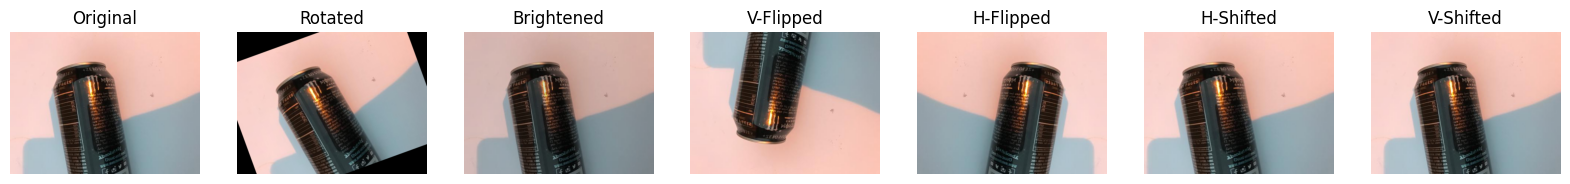

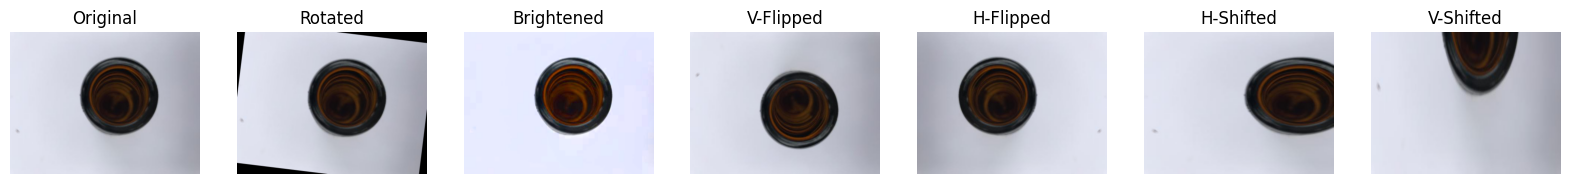

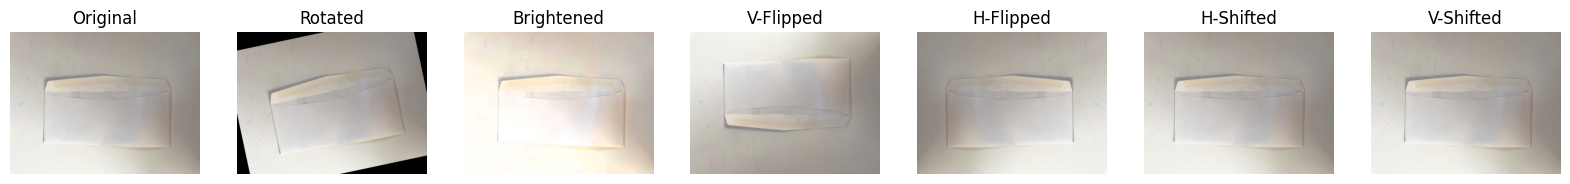

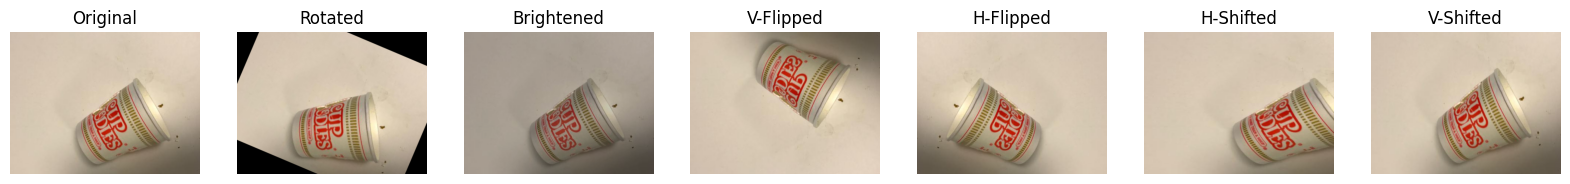

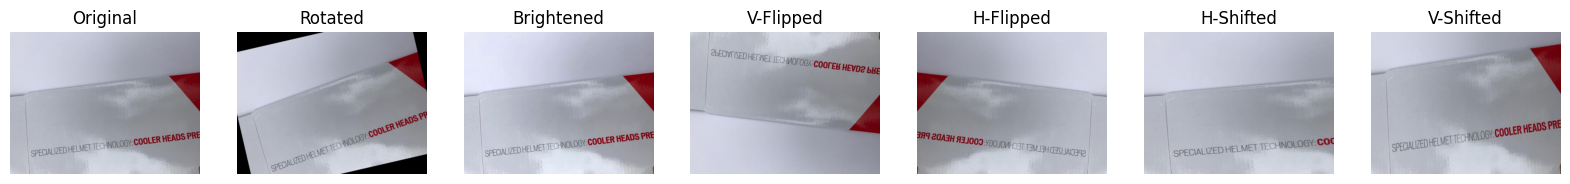

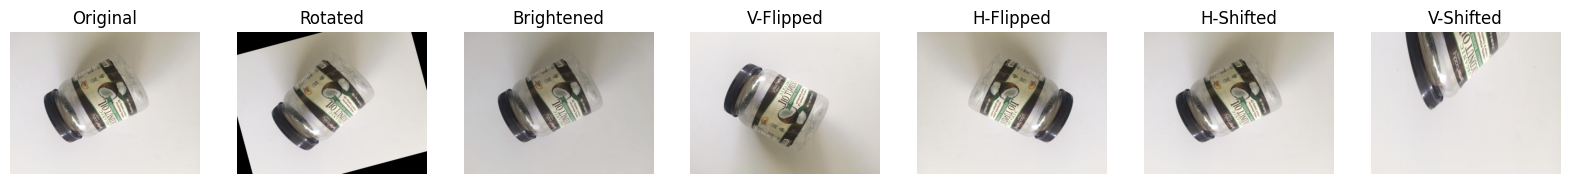

In [14]:
base_dir = '/kaggle/input/trash-net-original/dataset-resized/'
#augmented_dir = 'Trash_dataset_augmented_classify'
display_random_images_with_augmentations(base_dir)

## Split Data into (80% Train - 10% Val -10% Test )

In [5]:
# Set seed for reproducibility
seed = 42
np.random.seed(seed)

# Define paths
dataset_path = "/kaggle/input/trash-net-original/dataset-resized/"  # Original dataset folder containing class subfolders
output_path = "/kaggle/working/Trashfolder/split_Trashdataset_original_without_aug/"  # Folder where split data will be stored

# Get class names (assuming dataset_path has subfolders for each class)
class_names = os.listdir(dataset_path)

# Create directories for train, val, test
for split in ["train", "val", "test"]:
    for class_name in class_names:
        os.makedirs(os.path.join(output_path, split, class_name), exist_ok=True)

# Collect file paths and labels
file_paths = []
labels = []

for class_name in class_names:
    class_dir = os.path.join(dataset_path, class_name)
    images = [os.path.join(class_dir, img) for img in os.listdir(class_dir)]
    file_paths.extend(images)
    labels.extend([class_name] * len(images))

# Convert labels to numpy array
labels = np.array(labels)

# Split dataset: 80% train, 20% test_val
x_train, x_test_val, y_train, y_test_val = train_test_split(
    file_paths, labels, test_size=0.2, random_state=seed, shuffle=True, stratify=labels
)

# Split test_val into 50% test, 50% validation
x_test, x_val, y_test, y_val = train_test_split(
    x_test_val, y_test_val, test_size=0.5, random_state=seed, stratify=y_test_val
)

# Function to move images to respective folders
def move_files(file_list, label_list, split):
    for file, label in zip(file_list, label_list):
        dest = os.path.join(output_path, split, label, os.path.basename(file))
        shutil.copy(file, dest)

# Move images
move_files(x_train, y_train, "train")
move_files(x_val, y_val, "val")
move_files(x_test, y_test, "test")

print("Dataset split completed successfully!")

Dataset split completed successfully!


In [9]:
print("x_train",len(x_train))
print("y_train",y_train.shape)
print("x_val",len(x_val))
print("y_val",y_val.shape)
print("x_test",len(x_test))
print("y_test",y_test.shape)

x_train 2021
y_train (2021,)
x_val 253
y_val (253,)
x_test 253
y_test (253,)


In [22]:
# Define dataset path
data_dir = "/kaggle/working/Trashfolder/split_Trashdataset_original_without_aug"  # Root folder containing 'train', 'val', 'test'

# Function to count images per class in each split
def count_images_per_class(split,data_dir):
    split_path = os.path.join(data_dir, split)
    class_counts = {}

    for class_name in os.listdir(split_path):
        class_folder = os.path.join(split_path, class_name)
        if os.path.isdir(class_folder):
            num_images = len(os.listdir(class_folder))
            class_counts[class_name] = num_images

    return class_counts

# Get class distributions
train_counts = count_images_per_class("train",data_dir)
val_counts = count_images_per_class("val",data_dir)
test_counts = count_images_per_class("test",data_dir)

# Print results
print("Train Class Distribution:", train_counts)
print("Validation Class Distribution:", val_counts)
print("Test Class Distribution:", test_counts)




Train Class Distribution: {'plastic': 385, 'cardboard': 322, 'glass': 401, 'trash': 110, 'metal': 328, 'paper': 475}
Validation Class Distribution: {'plastic': 49, 'cardboard': 41, 'glass': 50, 'trash': 13, 'metal': 41, 'paper': 59}
Test Class Distribution: {'plastic': 48, 'cardboard': 40, 'glass': 50, 'trash': 14, 'metal': 41, 'paper': 60}


In [13]:
# Check the distribution of classes
#Checking Class Imbalance
#If we want to check whether the dataset is imbalanced, we can compute the percentage of each class
print("Train class distribution:", pd.Series(y_train).value_counts(normalize=True))
print("Test class distribution:", pd.Series(y_test).value_counts(normalize=True))
print("val class distribution:", pd.Series(y_val).value_counts(normalize=True))

Train class distribution: paper        0.235032
glass        0.198417
plastic      0.190500
metal        0.162296
cardboard    0.159327
trash        0.054429
Name: proportion, dtype: float64
Test class distribution: paper        0.237154
glass        0.197628
plastic      0.189723
metal        0.162055
cardboard    0.158103
trash        0.055336
Name: proportion, dtype: float64
val class distribution: paper        0.233202
glass        0.197628
plastic      0.193676
cardboard    0.162055
metal        0.162055
trash        0.051383
Name: proportion, dtype: float64


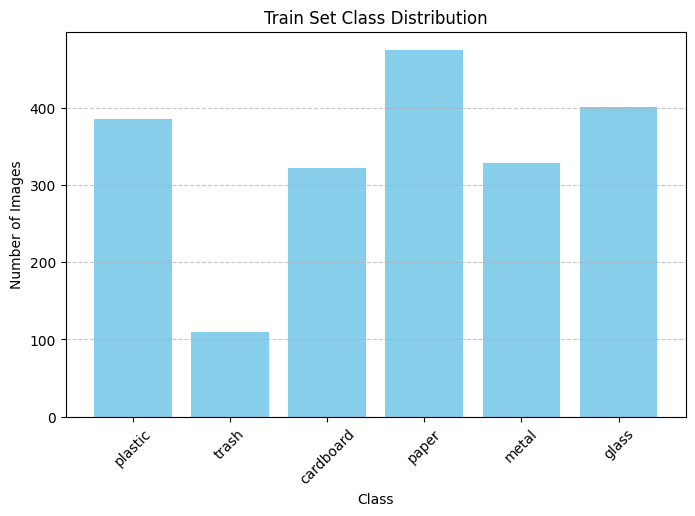

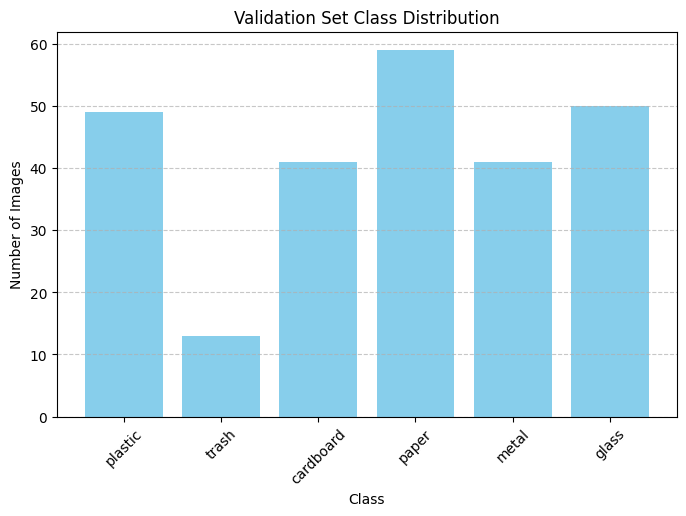

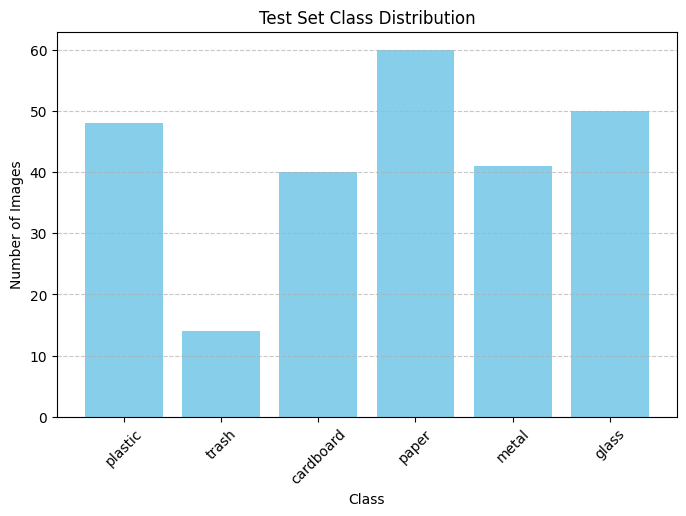

In [14]:
#Checking Class Distribution with Bar Plots
#To visualize how the dataset is distributed across different classes, we can use Matplotlib
# Function to plot class distribution
def plot_class_distribution(counts, split_name):
    plt.figure(figsize=(8, 5))
    plt.bar(counts.keys(), counts.values(), color="skyblue")
    plt.xlabel("Class")
    plt.ylabel("Number of Images")
    plt.title(f"{split_name} Set Class Distribution")
    plt.xticks(rotation=45)
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.show()

# Plot distributions
plot_class_distribution(train_counts, "Train")
plot_class_distribution(val_counts, "Validation")
plot_class_distribution(test_counts, "Test")

In [29]:
#Checking Class Imbalance
#If we want to check whether the dataset is imbalanced, we can compute the percentage of each class
# Function to compute class percentages
def compute_class_percentage(counts):
    total = sum(counts.values())
    percentages = {cls: round((count / total) * 100, 2) for cls, count in counts.items()}
    return percentages



In [30]:
# Get class percentages
train_percentages = compute_class_percentage(train_counts)
val_percentages = compute_class_percentage(val_counts)
test_percentages = compute_class_percentage(test_counts)

# Print results
print("Train Set Class Percentage:", train_percentages)
print("Validation Set Class Percentage:", val_percentages)
print("Test Set Class Percentage:", test_percentages)

Train Set Class Percentage: {'plastic': 19.05, 'cardboard': 15.93, 'glass': 19.84, 'trash': 5.44, 'metal': 16.23, 'paper': 23.5}
Validation Set Class Percentage: {'plastic': 19.37, 'cardboard': 16.21, 'glass': 19.76, 'trash': 5.14, 'metal': 16.21, 'paper': 23.32}
Test Set Class Percentage: {'plastic': 18.97, 'cardboard': 15.81, 'glass': 19.76, 'trash': 5.53, 'metal': 16.21, 'paper': 23.72}


In [16]:
import torch
#cal weights for train data 
class_counts = {
 'plastic': 19.05, 
 'trash': 5.44,
 'cardboard': 15.93,
 'paper': 23.5,
 'metal': 16.23, 
 'glass': 19.84}


# Convert to weights: inverse frequency
total = sum(class_counts.values())
weights = [total / v for v in class_counts.values()]
weights = torch.tensor(weights, dtype=torch.float32)

# Normalize (optional)
weights_train = weights / weights.sum()

print("Class Weights:", weights_train)

Class Weights: tensor([0.1157, 0.4052, 0.1384, 0.0938, 0.1358, 0.1111])


In [18]:
#cal wieghts for val data
import torch

class_counts = {
 'plastic': 19.37,
  'trash': 5.14, 
  'cardboard': 16.21,
  'paper': 23.32,
  'metal': 16.21,
  'glass': 19.76}


# Convert to weights: inverse frequency
total = sum(class_counts.values())
weights = [total / v for v in class_counts.values()]
weights = torch.tensor(weights, dtype=torch.float32)

# Normalize (optional)
weights_val = weights / weights.sum()

print("Class Weights:", weights_val)


Class Weights: tensor([0.1115, 0.4202, 0.1332, 0.0926, 0.1332, 0.1093])


## Random Augmentation on Train Dataset only

In [19]:
def random_augmentation_pipeline(dataset_path, augmented_path):
        split = "train"
        print('Starting augmentation with randomized distribution...')

    
        class_folders = glob(os.path.join(dataset_path, split, '*'))

        for class_folder in class_folders:
            class_name = os.path.basename(class_folder)
            save_dir = os.path.join(augmented_path, split, class_name)
            os.makedirs(save_dir, exist_ok=True)

            # Delete existing files if directory exists
            for f in glob(os.path.join(save_dir, '*')):
                os.remove(f)

            image_paths = glob(class_folder + '/*')
            all_augmented = []

            for image_path in image_paths:
                img = cv2.imread(image_path)
                if img is None:
                    continue

                # Generate all augmented variants
                variants = [
                    img,  # Original
                    rotation(img, 180),
                    brightness(img, 0.5, 1.5),
                    vertical_flip(img, 1),
                    horizontal_flip(img, 1),
                    horizontal_shift(img, 0.1),
                    vertical_shift(img, 0.3)
                ]

                # Save with random UUID filenames
                for variant in variants:
                    unique_id = uuid.uuid4().hex
                    ext = os.path.splitext(image_path)[1]
                    aug_filename = f"{unique_id}{ext}"
                    aug_path = os.path.join(save_dir, aug_filename)
                    cv2.imwrite(aug_path, variant)
                    all_augmented.append(aug_path)

            # Randomize file order in directory
            random.shuffle(all_augmented)

            # Rename files to force random access order
            for idx, old_path in enumerate(all_augmented):
                new_name = f"img_{idx:05d}{os.path.splitext(old_path)[1]}"
                new_path = os.path.join(save_dir, new_name)
                os.rename(old_path, new_path)

        print('Augmentation complete with randomized distribution!')



In [20]:
# Usage
# Ensure reproducibility
random.seed(42)
dataset_path = "/kaggle/working/Trashfolder/split_Trashdataset_original_without_aug"
augmented_path = "/kaggle/working/Trashfolder/split_Trash_dataset_augmented_classify_train_only"
random_augmentation_pipeline(dataset_path, augmented_path)

Starting augmentation with randomized distribution...
Augmentation complete with randomized distribution!


In [25]:
# Get class distributions after augmentation for train ,val dataset
data_dir = "/kaggle/working/Trashfolder/split_Trash_dataset_augmented_classify_train_only"
train_counts_aug = count_images_per_class("train",data_dir)

# Print results
print("Train Class Distribution after augmentation:", train_counts_aug)



Train Class Distribution after augmentation: {'plastic': 2695, 'cardboard': 2254, 'glass': 2807, 'trash': 770, 'metal': 2296, 'paper': 3325}


In [26]:
sum(train_counts_aug.values())

14147

In [31]:
# Get class percentages
train_percentages_aug = compute_class_percentage(train_counts_aug)

# Print results
print("Train Set Class Percentage:", train_percentages_aug)

Train Set Class Percentage: {'plastic': 19.05, 'cardboard': 15.93, 'glass': 19.84, 'trash': 5.44, 'metal': 16.23, 'paper': 23.5}


In [ ]:
!pwd

/content/drive/MyDrive/pytorch_practice


## Load Datasets Using ImageFolder

In [35]:

"""
torchvision.transforms	Often images need to be transformed
 (turned into numbers/processed/augmented) before being used with a model
transform: torchvision.transforms - what transformations would you like to do on the data?
target_transform - you can transform the targets (labels) if you like too.
"""
"""
All pre-trained models expect input images normalized in the same way, i.e. mini-batches of 3-channel RGB images of shape (3 x H x W)
, where H and W are expected to be at least 224. The images have to be loaded in to a range of [0, 1] and then normalized
using mean = [0.485, 0.456, 0.406] and std = [0.229, 0.224, 0.225]. You can use the following transform to normalize:
"""

"""image_transform = transforms.Compose(
    [transforms.Resize((224, 224)),              # Resize to 224x224
     transforms.ToTensor(), #images come as PIL format, we want to turn into Torch tensors
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
     ])"""
"""
Training (RandomResizedCrop):

Adds randomness to help the model generalize.

Encourages the model to be robust to object position/scale.

Validation (CenterCrop):

Ensures consistency when evaluating model performance.

Every image is preprocessed in the same way
"""
"""
image_transform = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

    ]),

    'test': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225]) ])
}"""

In [10]:
# 2. Data Preparation
def get_data_transforms(model_name):
    """Get appropriate transforms for each model architecture"""
    if model_name == 'inception_v3':
        # Inception v3 expects 299x299 inputs
        input_size = 299
        train_transform = transforms.Compose([
        transforms.RandomResizedCrop(input_size), 
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

    else:
        # Other models use 224x224 inputs
        input_size = 224
        train_transform = transforms.Compose([
        transforms.RandomResizedCrop(input_size),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, .5], [.5, .5, .5])])

    val_transform = transforms.Compose([
        transforms.Resize(int(input_size*1.15)),
        transforms.CenterCrop(input_size),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
         ])

    test_transform =  transforms.Compose([
        transforms.Resize(int(input_size*1.15)),
        transforms.CenterCrop(input_size),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225]) ])

    return train_transform, val_transform, test_transform, input_size

In [11]:
from torch.utils.data import SubsetRandomSampler
import random

def prepare_dataloaders(data_dir,data_dir_test, model_name, batch_size=16):
    """Prepare training and validation dataloaders"""
    train_dir = os.path.join(data_dir, 'train')
    val_dir = os.path.join(data_dir_test, 'val')
    test_dir= os.path.join(data_dir_test, 'test')
    train_transform, val_transform,test_transform ,input_size = get_data_transforms(model_name)

    # Create datasets
    train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
    val_dataset = datasets.ImageFolder(val_dir, transform=val_transform)
    test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)

    # Create dataloaders

    # Create DataLoaders # Turn datasets into iterables (batches)
    train_loader = DataLoader(  train_dataset,          #dataset to turn into iterable
                                batch_size=batch_size,  #how many samples per batch?
                                shuffle=True,           #shuffle data every epoch?
                                num_workers=4,             # number of CPU workers (8 is a good sweet spot on Kaggle)
                                pin_memory=True           # speeds up host→GPU copies
                                #drop_last=True,            # drop the last incomplete batch for better sync
                                #persistent_workers=True,   # keep workers alive across epochs
                                #prefetch_factor=2          # each worker preloads 4 batches ahead
                             )
    
    # Ensure reproducibility
    random.seed(42)
    val_indices = list(range(len(val_dataset)))
    random.shuffle(val_indices)  # shuffle once to mix classes
    val_sampler = SubsetRandomSampler(val_indices)
    val_loader = DataLoader(val_dataset,
                            batch_size=batch_size, 
                            sampler=val_sampler,
                            shuffle=False,# don't necessarily have to shuffle the testing data
                            num_workers=4,
                            pin_memory=True
                            #drop_last=False,
                            #persistent_workers=True,
                            #prefetch_factor=2          # lower prefetch since no augmentation
                           )
    # Ensure reproducibility
    random.seed(42)
    test_indices = list(range(len(test_dataset)))
    random.shuffle(test_indices)  # shuffle once to mix classes
    test_sampler = SubsetRandomSampler(test_indices)
    test_loader = DataLoader(test_dataset, 
                            batch_size=batch_size,
                            sampler=test_sampler,
                            shuffle=False,
                            num_workers=4,
                            pin_memory=True
                            #drop_last=False,
                            #persistent_workers=True,
                            #prefetch_factor=2          # lower prefetch since no augmentation
                                        
                            )

    # Check dataset sizes
    print(f"Train samples: {len(train_dataset)}, Batches: {len(train_loader)}")
    print(f"Validation samples: {len(val_dataset)}, Batches: {len(val_loader)}")
    print(f"Test samples: {len(test_dataset)}, Batches: {len(test_loader)}")

    class_names = train_dataset.classes
    return train_loader, val_loader,test_loader, class_names, input_size

In [36]:
train_transform, val_transform,test_transform ,input_size = get_data_transforms("base_densenet121")

In [37]:
print("train_transform=",train_transform)
print("val_transform=",val_transform)
print("test_transform=",test_transform)
print("input_size=",input_size)

train_transform= Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.08, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=None, contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
val_transform= Compose(
    Resize(size=257, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
test_transform= Compose(
    Resize(size=257, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
input_size= 224


In [39]:
# Define dataset paths
data_dir = "/kaggle/working/Trashfolder/split_Trash_dataset_augmented_classify_train_only/"  # Parent folder containing train, val, and test
data_dir_test="/kaggle/working/Trashfolder/split_Trashdataset_original_without_aug/"

In [40]:
# Load datasets using ImageFolder
train_dataset1 = ImageFolder(root=f"{data_dir}/train", transform=train_transform)
print("train_dataset=",train_dataset1)
val_dataset1 = ImageFolder(root=f"{data_dir_test}/val", transform=val_transform)
print("val_dataset=",val_dataset1)
test_dataset1 = ImageFolder(root=f"{data_dir_test}/test", transform=test_transform)
print("test_dataset=",test_dataset1)
# Print class-to-index mapping
print(train_dataset1.class_to_idx)  #{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}

train_dataset= Dataset ImageFolder
    Number of datapoints: 14147
    Root location: /kaggle/working/Trashfolder/split_Trash_dataset_augmented_classify_train_only//train
    StandardTransform
Transform: Compose(
               RandomResizedCrop(size=(224, 224), scale=(0.08, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
               RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
               ColorJitter(brightness=None, contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )
val_dataset= Dataset ImageFolder
    Number of datapoints: 253
    Root location: /kaggle/working/Trashfolder/split_Trashdataset_original_without_aug//val
    StandardTransform
Transform: Compose(
               Resize(size=257, interpolation=bilinear, max_size=None, antialias=True)
               CenterCrop(size=(224, 224))
              

In [41]:
print("type_train_dataset=",type(train_dataset1))

type_train_dataset= <class 'torchvision.datasets.folder.ImageFolder'>


## DataLoader to load Data into Models

**Prepare DataLoader**
Now we've got a dataset ready to go.

The next step is to prepare it with a torch.utils.data.DataLoader or DataLoader for short.

The DataLoader does what you think it might do.

It helps load data into a model.

For training and for inference.

It turns a large Dataset into a Python iterable of smaller chunks.

These smaller chunks are called batches or mini-batches and can be set by the batch_size parameter.

Why do this?

Because it's more computationally efficient.

In an ideal world you could do the forward pass and backward pass across all of your data at once.

But once you start using really large datasets, unless you've got infinite computing power, it's easier to break them up into batches.

It also gives your model more opportunities to improve.

With mini-batches (small portions of the data), gradient descent is performed more often per epoch (once per mini-batch rather than once per epoch).

**What's a good batch size?::**
Modern deep neural network training is typically based on mini-batch stochastic gradient optimization. While the use of large mini-batches increases the available computational parallelism, small batch training has been shown to provide improved generalization performance and allows a significantly smaller memory footprint, which might also be exploited to improve machine throughput.
In this paper, we review common assumptions on learning rate scaling and training duration, as a basis for an experimental comparison of test performance for different mini-batch sizes. We adopt a learning rate that corresponds to a constant average weight update per gradient calculation (i.e., per unit cost of computation), and point out that this results in a variance of the weight updates that increases linearly with the mini-batch size m.
The collected experimental results for the CIFAR-10, CIFAR-100 and ImageNet datasets show that increasing the mini-batch size progressively reduces the range of learning rates that provide stable convergence and acceptable test performance. On the other hand, small mini-batch sizes provide more up-to-date gradient calculations, which yields more stable and reliable training. The best performance has been consistently obtained for mini-batch sizes between m=2 and m=32, which contrasts with recent work advocating the use of mini-batch sizes in the thousands.

But since this is a value you can set (a hyperparameter) you can try all different kinds of values, though generally powers of 2 are used most often (e.g. 32, 64)

Sure! Let's break down the parameters in:  

```python
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
```

---

### **1️⃣ `test_dataset`**  
🔹 **This is the dataset** that you are loading into the `DataLoader`.  
🔹 It could be an instance of `torchvision.datasets.ImageFolder`, a `TensorDataset`, or a custom dataset.  
🔹 Example:  
   ```python
   test_dataset = torchvision.datasets.ImageFolder(root="path/to/test_data", transform=transform)
   ```

---

### **2️⃣ `batch_size=batch_size`**  
🔹 Defines **how many samples per batch** will be loaded into the model at once.  
🔹 **Why?** Instead of loading all data at once (which may not fit in memory), we process it in smaller groups (batches).  
🔹 Example: If `batch_size=32`, the DataLoader returns batches of **32 images per iteration**.  
🔹 **Trade-offs:**  
   - **Large batch sizes** → Faster training (fewer updates) but need more memory.  
   - **Small batch sizes** → More updates (more noise in training) but require less memory.  

---

### **3️⃣ `shuffle=False`**  
🔹 **Controls whether to shuffle the data before each epoch**.  
🔹 In testing, we **don't** shuffle (`False`) because we want to evaluate the model on the exact same order every time.  
🔹 For training, we **usually** set `shuffle=True` to **improve generalization** by feeding the model different orderings of data.

---

### **4️⃣ `num_workers=2`**  
🔹 **Defines how many CPU threads** to use for loading the data.  
🔹 More workers → Faster data loading **(if your system has multiple CPU cores)**.  
🔹 **Typical values:**  
   - `num_workers=0` → Uses the **main process only** (slower).  
   - `num_workers=2` → Uses **2 CPU cores** to load data in parallel.  
   - `num_workers=4` or `num_workers=8` → Faster loading (good for large datasets).  
   - **Warning**: If using Windows, you may need `num_workers=0` to avoid multiprocessing issues.  

---

### **📝 Summary**  
| Parameter        | Purpose |
|-----------------|---------|
| `test_dataset`  | The dataset to be loaded |
| `batch_size`    | Number of samples per batch |
| `shuffle=False` | Keeps test data in order (no shuffling) |
| `num_workers=2` | Uses 2 CPU cores for loading data |

---

### **🚀 Example Usage**
```python
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Define transformations
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# Load test dataset
test_dataset = datasets.ImageFolder(root="path/to/test_data", transform=transform)

# Create DataLoader
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

# Iterate over test data
for images, labels in test_loader:
    print(f"Batch size: {images.shape}")  # Output: torch.Size([32, 3, 128, 128])
```

---

### **💡 When to Change These Values?**
- **For training** → `shuffle=True`
- **For testing** → `shuffle=False`
- **Large dataset**? → Increase `num_workers`
- **Limited RAM?** → Reduce `batch_size`

Would you like to tune these settings for your specific dataset? 😊

In [53]:
"""torch.utils.data.DataLoader	Creates
a Python iterable over a dataset (created with torch.utils.data.Dataset).
DataLoader(dataset, batch_size=1, shuffle=False, sampler=None,
           batch_sampler=None, num_workers=0, collate_fn=None,
           pin_memory=False, drop_last=False, timeout=0,
           worker_init_fn=None, *, prefetch_factor=2,
           persistent_workers=False)
The most important argument of DataLoader constructor is dataset,
which indicates a dataset object to load data from. PyTorch supports two different types of datasets:
map-style datasets,
iterable-style datasets.
1-dataset (Dataset) – dataset from which to load the data.
2-batch_size (int, optional) – how many samples per batch to load (default: 1).
3-shuffle (bool, optional) – set to True to have the data reshuffled at every epoch (default: False).
"""

# Define batch size
batch_size = 16

# Create DataLoaders # Turn datasets into iterables (batches)
train_loader = DataLoader(train_dataset,          #dataset to turn into iterable
                          batch_size=batch_size,  #how many samples per batch?
                          shuffle=True,           #shuffle data every epoch?
                          num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,# don't necessarily have to shuffle the testing data
                        num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

# Check dataset sizes
print(f"Train samples: {len(train_dataset)}, Batches: {len(train_loader)}")
print(f"Validation samples: {len(val_dataset)}, Batches: {len(val_loader)}")
print(f"Test samples: {len(test_dataset)}, Batches: {len(test_loader)}")

Train samples: 14147, Batches: 885
Validation samples: 1771, Batches: 111
Test samples: 253, Batches: 16


In [43]:
batch_size=16
# Create DataLoaders # Turn datasets into iterables (batches)
train_loader1 = DataLoader(  train_dataset1,          #dataset to turn into iterable
                                batch_size=batch_size,  #how many samples per batch?
                                shuffle=True,           #shuffle data every epoch?
                                num_workers=4,             # number of CPU workers (8 is a good sweet spot on Kaggle)
                                pin_memory=True,           # speeds up host→GPU copies
                                drop_last=True,            # drop the last incomplete batch for better sync
                                persistent_workers=True,   # keep workers alive across epochs
                                prefetch_factor=2          # each worker preloads 4 batches ahead
                             )
    
# Ensure reproducibility
random.seed(42)
val_indices1 = list(range(len(val_dataset1)))
random.shuffle(val_indices1)  # shuffle once to mix classes
val_sampler1 = SubsetRandomSampler(val_indices1)
val_loader1= DataLoader(val_dataset1,
                            batch_size=batch_size, 
                            sampler=val_sampler1,
                            shuffle=False,# don't necessarily have to shuffle the testing data
                            num_workers=4,
                            pin_memory=True,
                            drop_last=False,
                            persistent_workers=True,
                            prefetch_factor=2          # lower prefetch since no augmentation
                           )
# Ensure reproducibility
random.seed(42)
test_indices1 = list(range(len(test_dataset1)))
random.shuffle(test_indices1)  # shuffle once to mix classes
test_sampler1 = SubsetRandomSampler(test_indices1)
test_loader1 = DataLoader(test_dataset1, 
                            batch_size=batch_size,
                            sampler=test_sampler1,
                            shuffle=False,
                            num_workers=4,
                            pin_memory=True,
                            drop_last=False,
                            persistent_workers=True,
                            prefetch_factor=2          # lower prefetch since no augmentation
                                        
                            )

In [44]:
# Check dataset sizes
print(f"Train samples: {len(train_dataset1)}, Batches: {len(train_loader1)}")
print(f"Validation samples: {len(val_dataset1)}, Batches: {len(val_loader1)}")
print(f"Test samples: {len(test_dataset1)}, Batches: {len(test_loader1)}")

Train samples: 14147, Batches: 884
Validation samples: 253, Batches: 16
Test samples: 253, Batches: 16


In [52]:
batch_imgs, batch_lbls = next(iter(train_loader1))
print("train batch labels:", batch_lbls.tolist())

train batch labels: [3, 2, 4, 4, 3, 1, 1, 4, 3, 5, 3, 4, 0, 1, 5, 0]


In [53]:
batch_imgs, batch_lbls = next(iter(val_loader1))
print("Val batch labels:", batch_lbls.tolist())

Val batch labels: [2, 4, 4, 2, 0, 4, 2, 0, 4, 5, 1, 1, 4, 4, 4, 0]


In [54]:
batch_imgs, batch_lbls = next(iter(test_loader1))
print("test batch labels:", batch_lbls.tolist())

test batch labels: [2, 3, 1, 1, 3, 4, 2, 3, 3, 4, 4, 3, 2, 3, 0, 2]


In [49]:
random.seed(22)
#Val loader: shuffle=False but use a fixed random sampler once
print("len(val_dataset)=",len(val_dataset1))
print(range(len(val_dataset1)))
val_indices2 = list(range(len(val_dataset1)))
random.shuffle(val_indices2)   # shuffle once
val_sampler2 = SubsetRandomSampler(val_indices2 )
print ("train_indices=",val_indices2 )
print("val_sampler=",val_sampler2)

len(val_dataset)= 253
range(0, 253)
train_indices= [151, 183, 182, 19, 154, 196, 207, 124, 120, 216, 65, 127, 215, 18, 140, 244, 56, 174, 106, 42, 112, 235, 172, 208, 52, 125, 0, 205, 130, 201, 86, 41, 38, 70, 221, 193, 236, 11, 10, 115, 97, 126, 145, 206, 204, 164, 29, 195, 137, 118, 246, 3, 142, 40, 128, 138, 57, 231, 73, 39, 54, 53, 212, 243, 4, 116, 119, 168, 133, 26, 157, 92, 250, 99, 98, 94, 249, 32, 234, 27, 225, 184, 173, 188, 123, 162, 200, 55, 171, 239, 80, 21, 190, 146, 122, 251, 44, 185, 161, 2, 121, 33, 77, 155, 238, 229, 176, 82, 237, 93, 111, 60, 163, 228, 242, 197, 74, 17, 220, 90, 63, 209, 108, 222, 58, 75, 148, 37, 31, 105, 194, 13, 158, 51, 34, 16, 9, 160, 217, 159, 84, 230, 89, 96, 167, 7, 43, 49, 117, 24, 1, 102, 61, 211, 50, 14, 103, 165, 25, 91, 113, 23, 22, 109, 213, 191, 134, 139, 143, 152, 223, 76, 248, 214, 180, 95, 210, 78, 192, 169, 101, 104, 132, 72, 129, 64, 218, 8, 136, 87, 240, 226, 203, 177, 170, 69, 71, 36, 131, 241, 199, 219, 100, 252, 66, 85, 247, 8

In [50]:
# Access image paths and labels from the dataset
image_paths = [val_dataset1.samples[i][0] for i in val_indices2[:10]]
labels = [val_dataset1.samples[i][1] for i in val_indices2[:10]]
class_names = val_dataset1.classes

print("\nSample Images from train_sampler:")
for i, (path, label_idx) in enumerate(zip(image_paths, labels)):
    print(f"{i+1}. {path} --> {class_names[label_idx]}")


Sample Images from train_sampler:
1. /kaggle/working/Trashfolder/split_Trashdataset_original_without_aug//val/paper/paper286.jpg --> paper
2. /kaggle/working/Trashfolder/split_Trashdataset_original_without_aug//val/paper/paper60.jpg --> paper
3. /kaggle/working/Trashfolder/split_Trashdataset_original_without_aug//val/paper/paper592.jpg --> paper
4. /kaggle/working/Trashfolder/split_Trashdataset_original_without_aug//val/cardboard/cardboard289.jpg --> cardboard
5. /kaggle/working/Trashfolder/split_Trashdataset_original_without_aug//val/paper/paper33.jpg --> paper
6. /kaggle/working/Trashfolder/split_Trashdataset_original_without_aug//val/plastic/plastic121.jpg --> plastic
7. /kaggle/working/Trashfolder/split_Trashdataset_original_without_aug//val/plastic/plastic219.jpg --> plastic
8. /kaggle/working/Trashfolder/split_Trashdataset_original_without_aug//val/metal/metal59.jpg --> metal
9. /kaggle/working/Trashfolder/split_Trashdataset_original_without_aug//val/metal/metal401.jpg --> metal

In [56]:
# Check out what's inside the training dataloader
train_features_batch, train_labels_batch = next(iter(train_loader1))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([16, 3, 224, 224]), torch.Size([16]))

In [57]:
# Get class index-to-name mapping from dataset
idx_to_class = {v: k for k, v in train_dataset1.class_to_idx.items()}
class_names = list(idx_to_class.values())

# Function to unnormalize and plot a batch of images
def plot_images(images, labels, num_images=15):
    plt.figure(figsize=(15, 10))

    for i in range(min(num_images, len(images))):
        img =  images[i].numpy().transpose((1, 2, 0))
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean  # unnormalize (assuming normalization with mean, std)
        img_np= np.clip(img, 0, 1) # ensure pixel values are in [0,1]
        plt.subplot(5, 5, i + 1)
        plt.imshow(img_np)
        plt.title(class_names[labels[i].item()])
        plt.axis('off')

    plt.tight_layout()
    plt.show()

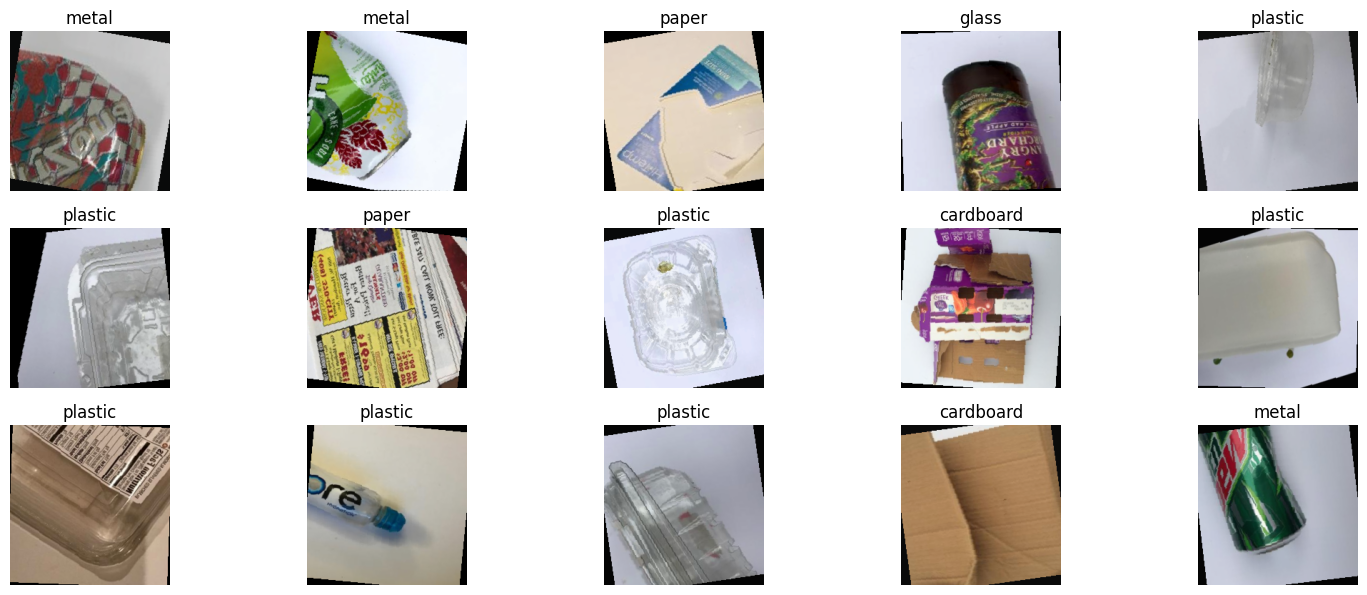

In [58]:
# Example usage:
# Get one batch from DataLoader
train_features_batch, train_labels_batch = next(iter(train_loader1))
plot_images(train_features_batch, train_labels_batch)

In [59]:
# Check out what's inside the val dataloader
val_features_batch, val_labels_batch = next(iter(val_loader1))
print(val_labels_batch) 

tensor([3, 0, 3, 2, 0, 0, 3, 4, 4, 4, 2, 1, 2, 0, 2, 4])


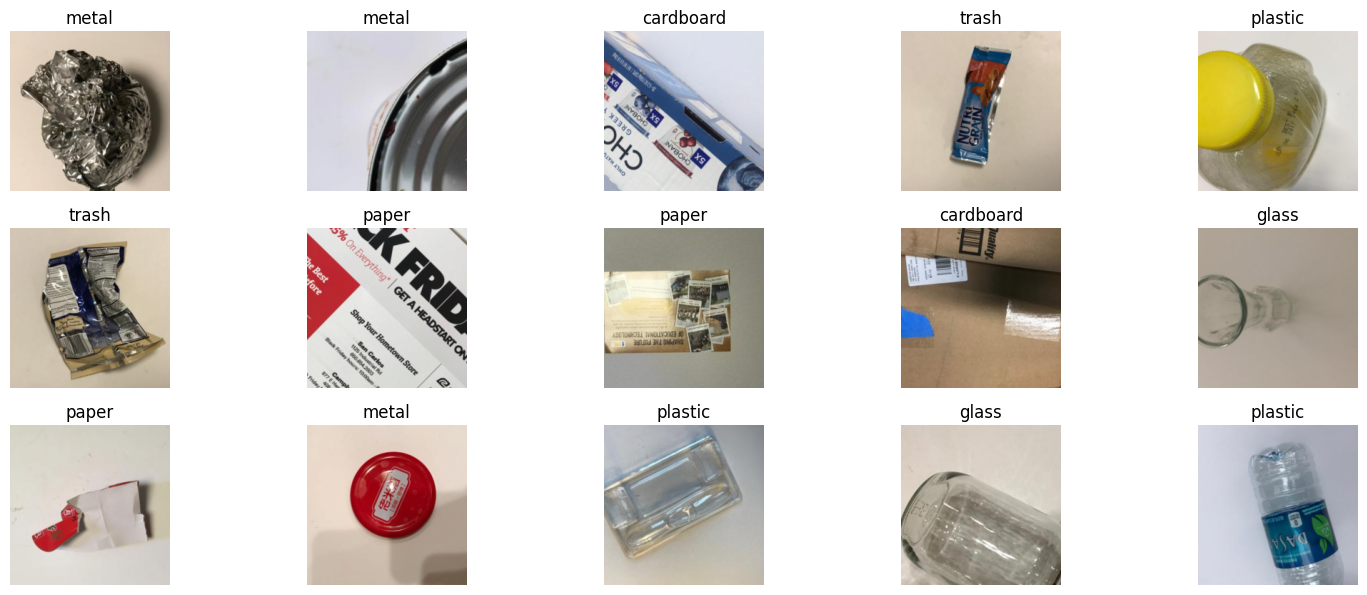

In [60]:
# Example usage:
# Get one batch from DataLoader
train_features_batch, train_labels_batch = next(iter(val_loader1))
plot_images(train_features_batch, train_labels_batch)

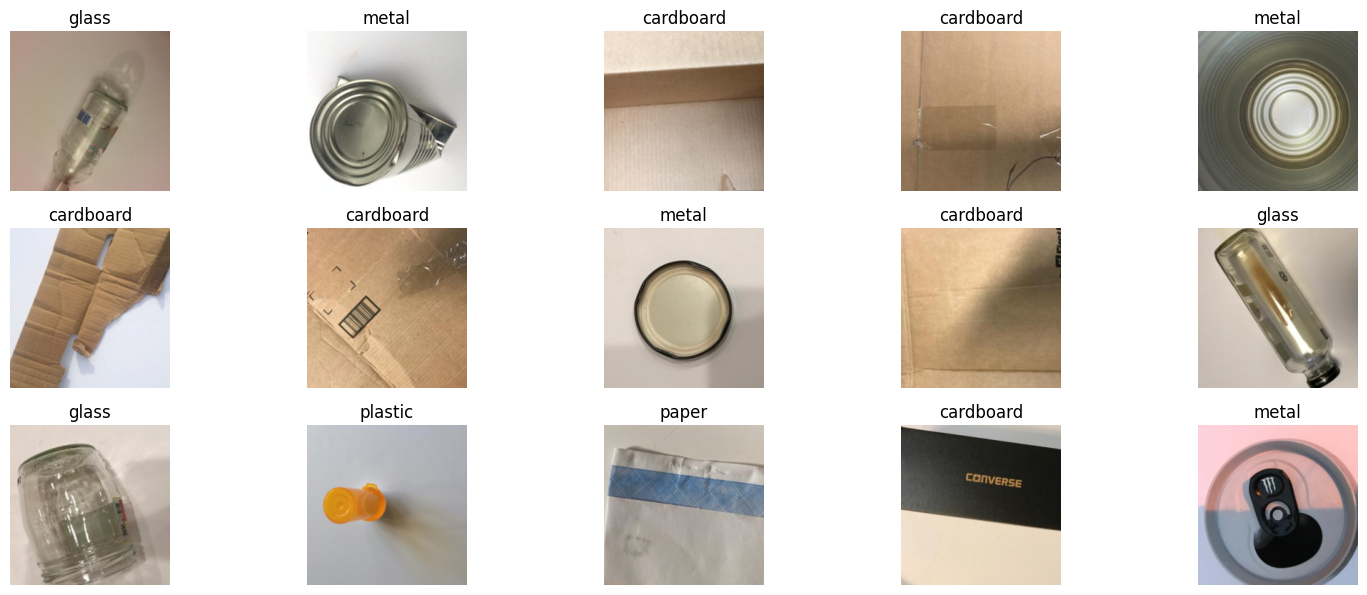

In [61]:
# Example usage:
# Get one batch from DataLoader
train_features_batch, train_labels_batch = next(iter(test_loader1))
plot_images(train_features_batch, train_labels_batch)

## Creating a training loop and training a model on batches of data (for_all)


Why Use Batches for Training? **bold text**
Since our dataset is large and contains thousands of trash images, we can't pass all data through the model at once (it would overwhelm the memory). Instead, we split the dataset into smaller chunks (batches), and the model updates its weights per batch — this is called mini-batch training.
In our case, we’re using a batch_size = 16, so every batch will consist of 16 images and their corresponding labels. These batches are delivered one at a time through the train_loader, val_loader, and test_loader.
Each batch will be processed during:
•	Training to update weights
•	Validation to monitor performance without updating weights
•	Testing to evaluate generalization on unseen data


🔄 What Happens in Each Epoch?
An epoch is one complete pass over the entire training dataset.
In each epoch, we perform:
1.	Training Phase
o	Loop over all training batches
o	Perform forward pass
o	Calculate loss
o	Backpropagate gradients
o	Update weights
o	Track accuracy and loss per batch
2.	Validation Phase
o	Loop over all validation batches
o	Perform forward pass
o	Compute loss (no gradient updates)
o	Track accuracy and loss


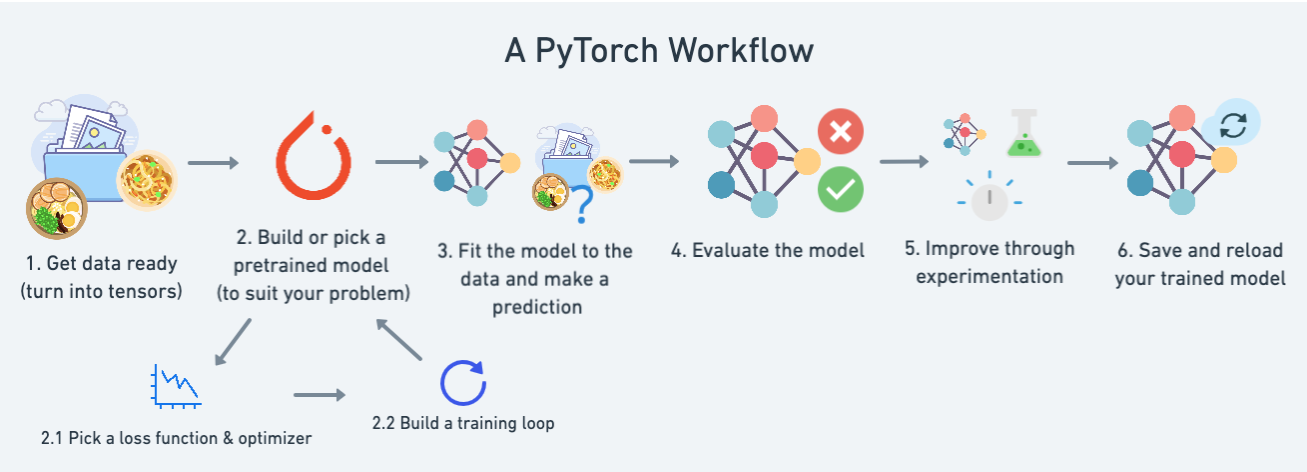

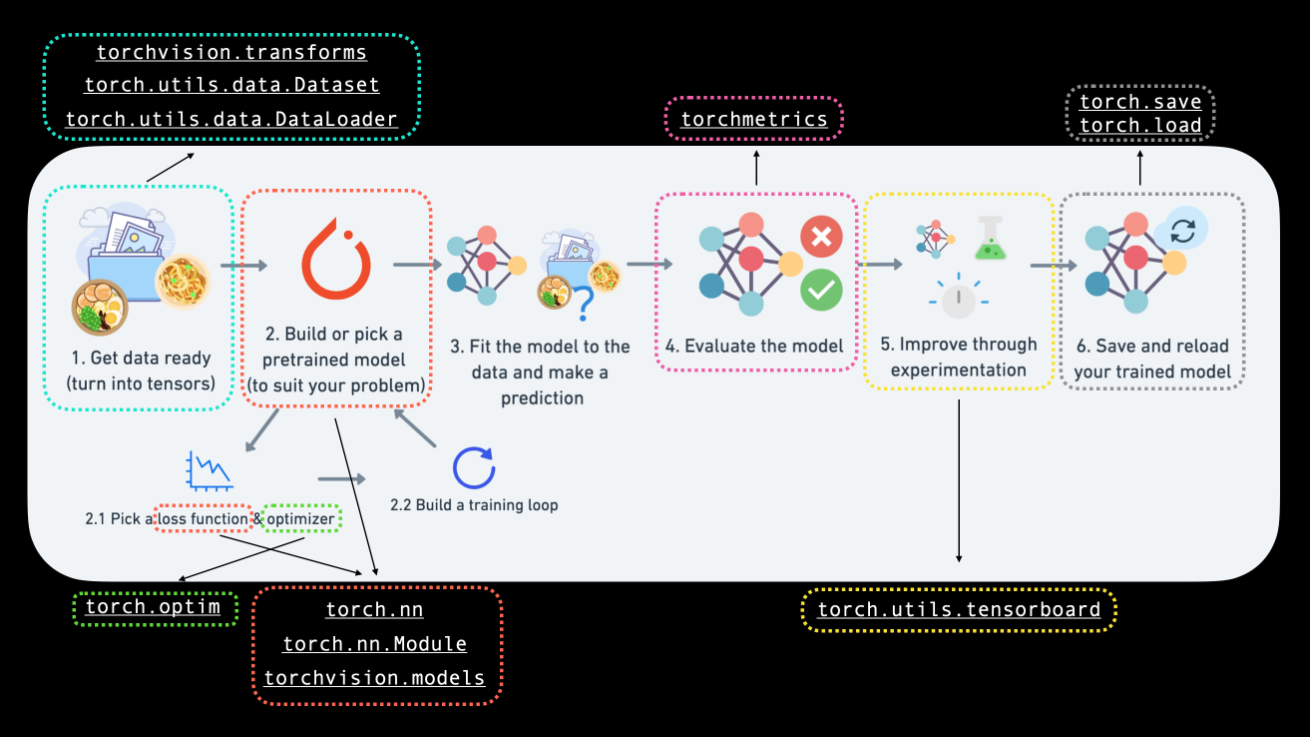

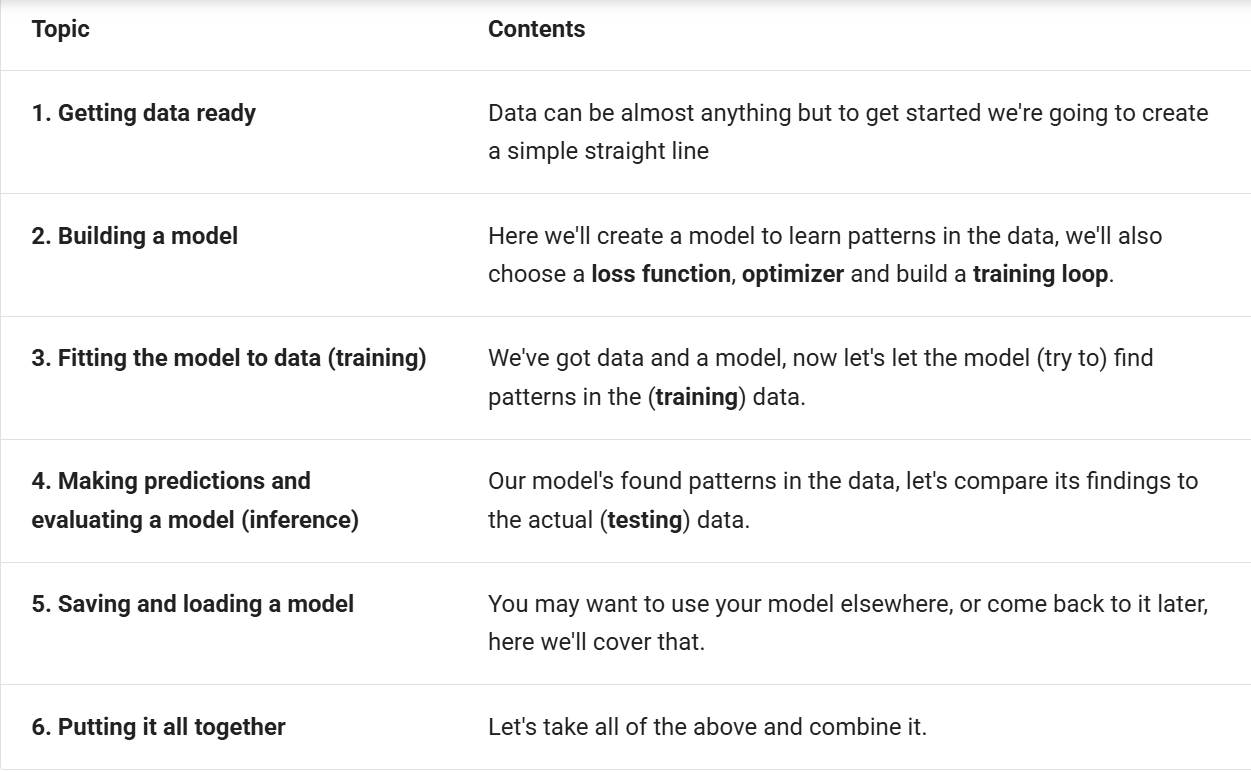


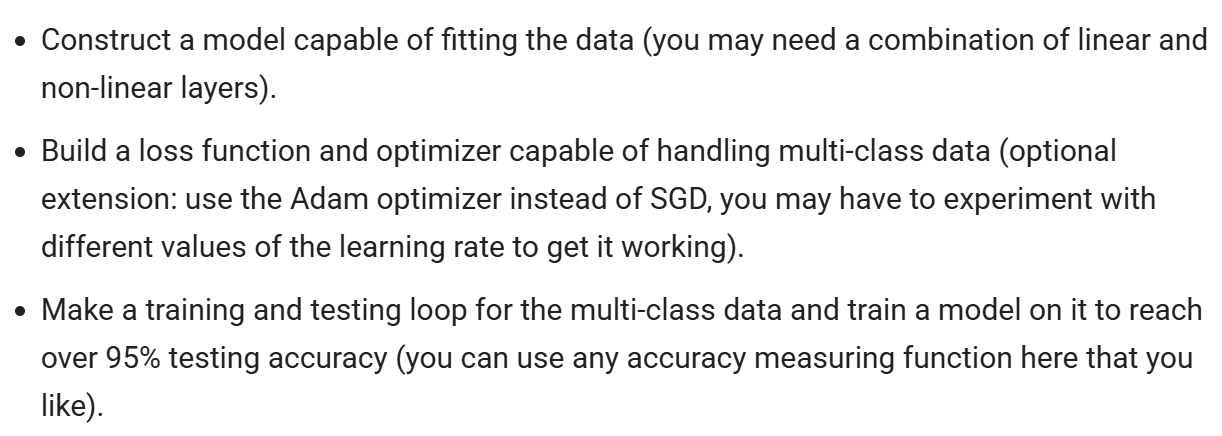

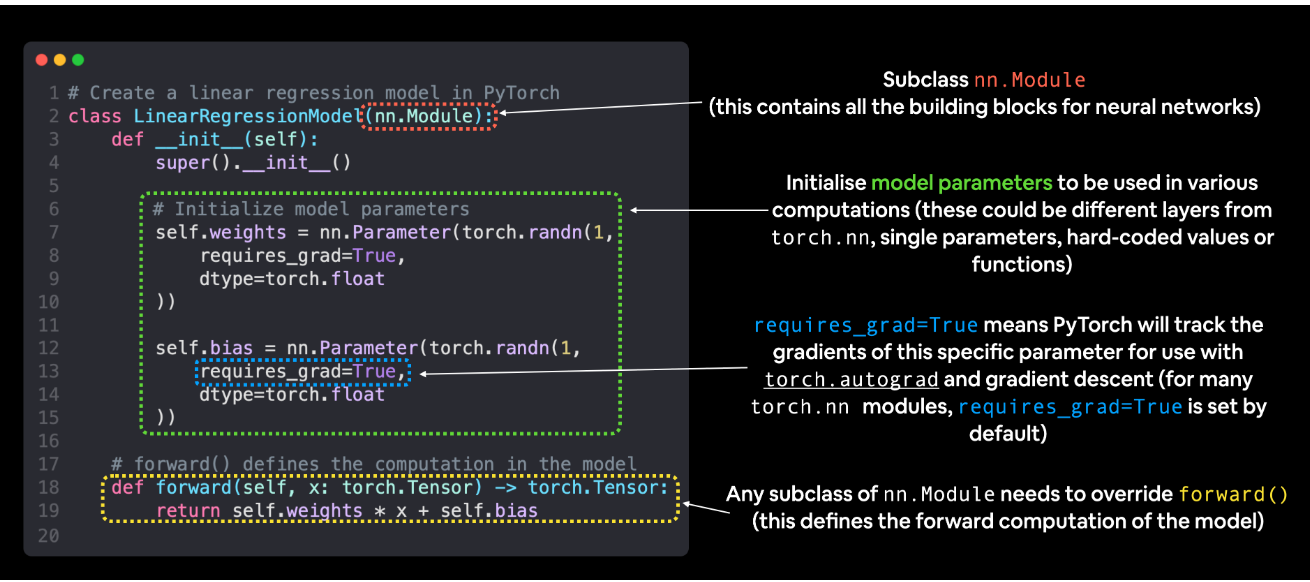

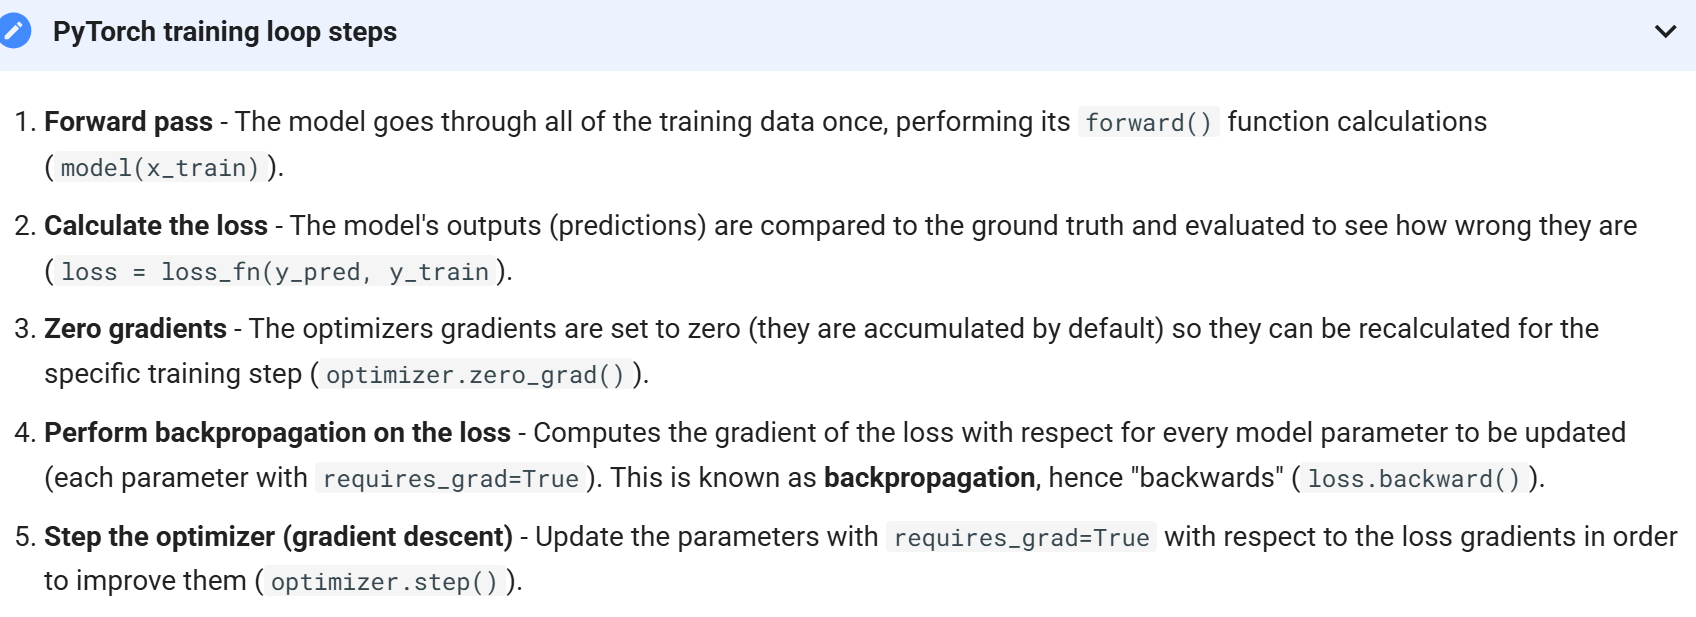

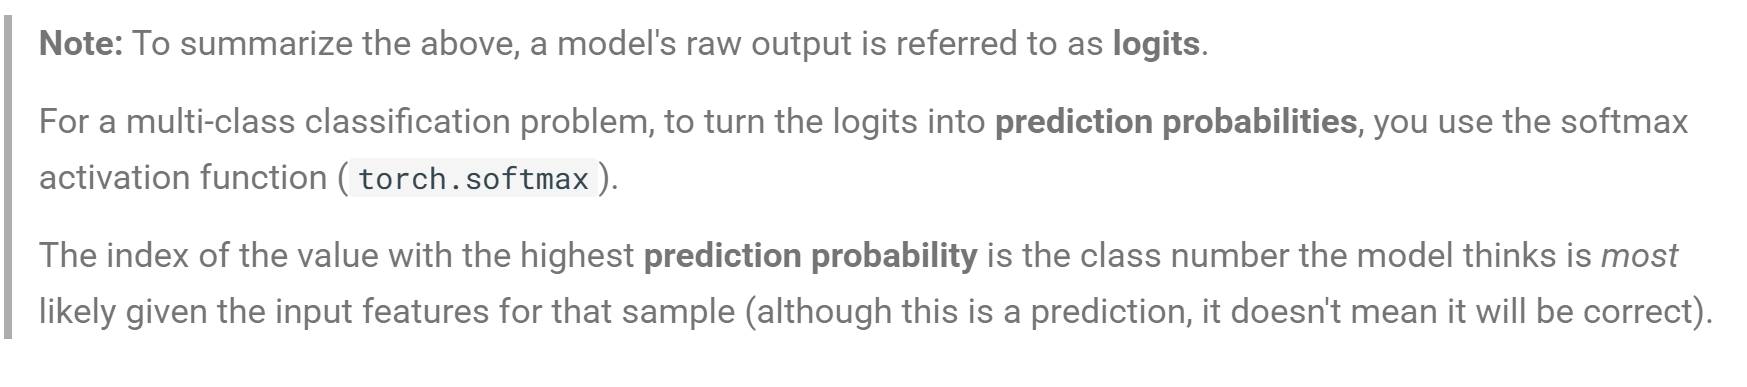

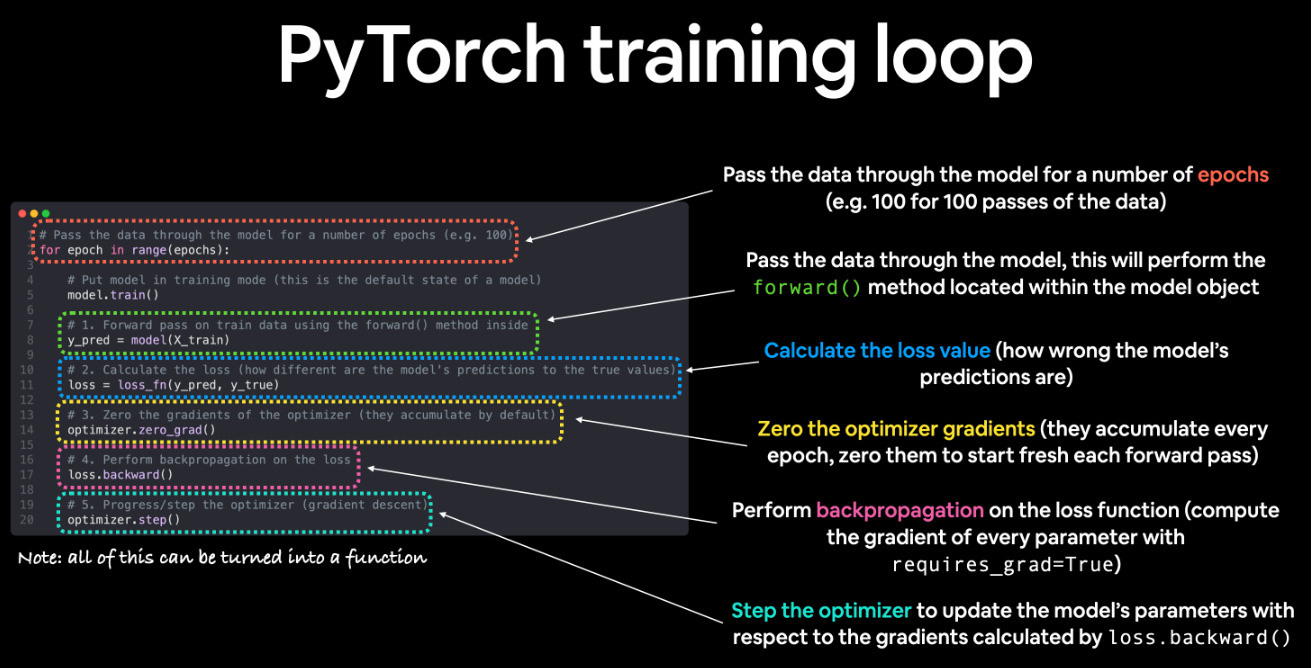

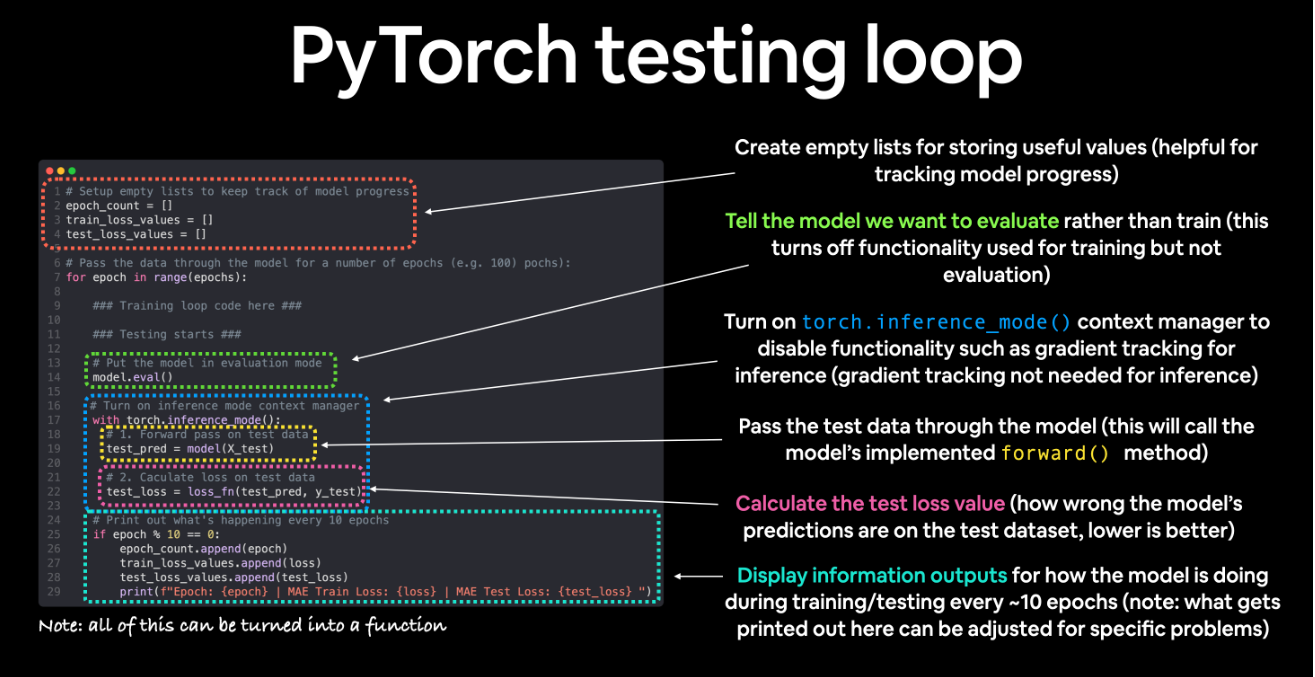

**Creating a function to time our experiments**
Loss function and optimizer ready!

It's time to start training a model.

But how about we do a little experiment while we train.

I mean, let's make a timing function to measure the time it takes our model to train on CPU versus using a GPU.

In [63]:
from timeit import default_timer as timer
def print_train_time(start: float, end: float, device: torch.device = None):
    """Prints difference between start and end time.

    Args:
        start (float): Start time of computation (preferred in timeit format).
        end (float): End time of computation.
        device ([type], optional): Device that compute is running on. Defaults to None.

    Returns:
        float: time between start and end in seconds (higher is longer).
    """
    total_time = end - start
    print(f"Train time on {device}: {total_time:.3f} seconds")
    return total_time


"""
# Import tqdm for progress bar
from tqdm.auto import tqdm

# Set the seed and start the timer
torch.manual_seed(42)
train_time_start_on_cpu = timer()

# Set the number of epochs (we'll keep this small for faster training times)
epochs = 3

# Create training and testing loop
for epoch in tqdm(range(epochs)):

"""

"\n# Import tqdm for progress bar\nfrom tqdm.auto import tqdm\n\n# Set the seed and start the timer\ntorch.manual_seed(42)\ntrain_time_start_on_cpu = timer()\n\n# Set the number of epochs (we'll keep this small for faster training times)\nepochs = 3\n\n# Create training and testing loop\nfor epoch in tqdm(range(epochs)):\n\n"

In [73]:
import torchmetrics

In [ ]:
accuracy=torchmetrics.Accuracy()
f1=torchmetrics.F1Score()
precesion=torchmetrics.Precision()
recall=torchmetrics.Recall()

In [ ]:
import torchmetrics
accuracy  = torchmetrics.Accuracy(task="multiclass",
                                               num_classes=6)
precision = torchmetrics.Precision(task="multiclass",
                                                num_classes=6)

In [ ]:
if epoch == 0:
                    y_pred_probs = F.softmax(y_logits, dim=1)
                    print(f"\n[{model_name}] Sample logits:\n", y_logits[:5])
                    print(f"[{model_name}] Sample probabilities:\n", y_pred_probs[:5])

In [ ]:
import torch
import time
import torch.nn.functional as F
from tqdm import tqdm
torch.manual_seed(42)

def calculate_accuracy(y_true, y_pred):
    predicted = torch.argmax(y_pred, dim=1)
    correct = (predicted == y_true).sum().item()
    return correct / len(y_true)

def fit_model(model, model_name, train_iterator, valid_iterator,loss_criterion, optimizer,epochs, device):
    """
    Trains and evaluates a given PyTorch model.

    Args:
        model (torch.nn.Module): The model to train.
        model_name (str): Name of the model (used for printing/logging).
        train_iterator (DataLoader): DataLoader for training data.
        valid_iterator (DataLoader): DataLoader for validation data.
        optimizer (torch.optim.Optimizer): Optimizer.
        loss_criterion (torch.nn.Module): Loss function.
        epochs (int): Number of training epochs.
        device (torch.device): Device to run the model on ('cuda' or 'cpu').
    """
    best_valid_loss = float('inf')
    model = model.to(device)
    #loss_criterion = nn.CrossEntropyLoss()
    #opt = optim.optimizer(model.parameters(), lr, momentum)
    for epoch in range(epochs):
        start_time = time.time()

        # ---------- Training ----------
        model.train()
        train_loss, train_acc = 0.0, 0.0

        for images, labels in tqdm(train_iterator):
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            y_logits = model(images)
            loss = loss_criterion(y_logits, labels)

            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Accuracy and loss
            train_loss += loss.item()
            train_acc += calculate_accuracy(labels, y_logits)

        # ---------- Validation ----------
        model.eval()
        val_loss, val_acc = 0.0, 0.0

        with torch.inference_mode():
            for images, labels in tqdm(valid_iterator):
                images, labels = images.to(device), labels.to(device)

                y_logits = model(images)
                loss = loss_criterion(y_logits, labels)

                # Debug: Print predictions for first epoch
                

                y_pred = y_logits.argmax(dim=1)
                val_loss += loss.item()
                val_acc += (y_pred == labels).sum().item() / len(labels)

        if val_loss < best_valid_loss:
                    best_valid_loss = val_loss
                    torch.save(model.state_dict(), f'{model_name}.pt')

        # ---------- Epoch Summary ----------
        end_time = time.time()
        print(f"Epoch [{epoch+1}/{epochs}] - {model_name} - Time: {end_time - start_time:.2f}s")
        print(f"\tTrain Loss: {train_loss/len(train_iterator):.4f}, Train Acc: {train_acc/len(train_iterator):.4f}")
        print(f"\tVal Loss: {val_loss/len(valid_iterator):.4f}, Val   Acc: {val_acc/len(valid_iterator):.4f}")


In [ ]:
import os
import time
import torch
import torch.nn.functional as F
from sklearn.metrics import precision_score, recall_score, f1_score
import mlflow

def fit_model(model,
              model_name,
              train_loader,
              valid_loader,
              loss_criterion,
              optimizer,
              epochs,
              device,
              save_dir="checkpoints",
              early_stopping_patience=3):
    """
    Trains and evaluates a PyTorch model, logging to MLflow,
    with per-epoch loss/acc/prec/rec/f1, checkpointing, and early stopping.
    """
    os.makedirs(save_dir, exist_ok=True)
    best_val_loss = float('inf')
    epochs_no_improve = 0

    model = model.to(device)

    # Start MLflow run
    mlflow.start_run(run_name=model_name)
    mlflow.log_params({
        "model_name": model_name,
        "epochs": epochs,
        "optimizer": optimizer.__class__.__name__,
        "lr": optimizer.param_groups[0]['lr'],
        "early_stopping_patience": early_stopping_patience
    })

    for epoch in range(1, epochs + 1):
        start = time.time()
        # --- Training ---
        model.train()
        train_loss = 0.0
        train_correct = 0
        total_train = 0

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(X)
            loss = loss_criterion(logits, y)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * X.size(0)
            preds = logits.argmax(dim=1)
            train_correct += (preds == y).sum().item()
            total_train += X.size(0)

        avg_train_loss = train_loss / total_train
        train_acc = train_correct / total_train

        # --- Validation ---
        model.eval()
        val_loss = 0.0
        val_correct = 0
        total_val = 0
        all_preds, all_labels = [], []

        with torch.inference_mode():
            for X, y in valid_loader:
                X, y = X.to(device), y.to(device)
                logits = model(X)
                loss = loss_criterion(logits, y)

                val_loss += loss.item() * X.size(0)
                preds = logits.argmax(dim=1)
                val_correct += (preds == y).sum().item()
                total_val += X.size(0)

                all_preds .extend(preds.cpu().tolist())
                all_labels.extend(y.cpu().tolist())

        avg_val_loss = val_loss / total_val
        val_acc = val_correct / total_val
        val_prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
        val_rec  = recall_score(   all_labels, all_preds, average='macro', zero_division=0)
        val_f1   = f1_score(       all_labels, all_preds, average='macro', zero_division=0)

        # Log metrics to MLflow
        mlflow.log_metrics({
            "train_loss": avg_train_loss,
            "train_acc":  train_acc,
            "val_loss":   avg_val_loss,
            "val_acc":    val_acc,
            "val_prec":   val_prec,
            "val_rec":    val_rec,
            "val_f1":     val_f1
        }, step=epoch)

        # Checkpoint & Early Stopping
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            epochs_no_improve = 0
            ckpt_path = os.path.join(save_dir, f"{model_name}_best.pt")
            torch.save(model.state_dict(), ckpt_path)
            mlflow.log_artifact(ckpt_path, artifact_path="model_checkpoints")
            ckpt_msg = "✔️ Saved"
        else:
            epochs_no_improve += 1
            ckpt_msg = ""
            if epochs_no_improve >= early_stopping_patience:
                print(f"⛔ Early stopping at epoch {epoch}")
                break

        # Epoch summary
        elapsed = time.time() - start
        print(f"\nEpoch {epoch}/{epochs} [{elapsed:.1f}s]")
        print(f" Train ▶ loss: {avg_train_loss:.4f} | acc: {train_acc:.4f}")
        print(f" Val   ▶ loss: {avg_val_loss:.4f} | acc: {val_acc:.4f} | "
              f"prec: {val_prec:.4f} | rec: {val_rec:.4f} | f1: {val_f1:.4f} {ckpt_msg}")

    # End MLflow run
    mlflow.end_run()

    return {
        "train_loss": avg_train_loss, "train_acc": train_acc,
        "val_loss": avg_val_loss,     "val_acc": val_acc,
        "val_prec": val_prec,         "val_rec": val_rec,
        "val_f1": val_f1
    }


In [ ]:
# Setup metric and make sure it's on the target device
torchmetrics_accuracy = Accuracy(task='multiclass', num_classes=4).to(device)

# Calculate accuracy
torchmetrics_accuracy(y_preds, y_blob_test)

## Evaluating predictions with a PyTorch multi-class model (Inference mode)
It looks like our trained model is performing pretty well.

But to make sure of this, let's make some predictions and visualize them.

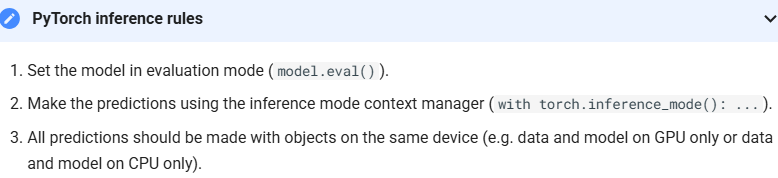

You probably noticed we used torch.inference_mode() as a context manager (that's what the with torch.inference_mode(): is) to make the predictions.

As the name suggests, torch.inference_mode() is used when using a model for inference (making predictions).

torch.inference_mode() turns off a bunch of things (like gradient tracking, which is necessary for training but not for inference) to make forward-passes (data going through the forward() method) faster.

Note: In older PyTorch code, you may also see torch.no_grad() being used for inference. While torch.inference_mode() and torch.no_grad() do similar things, torch.inference_mode() is newer, potentially faster and preferred

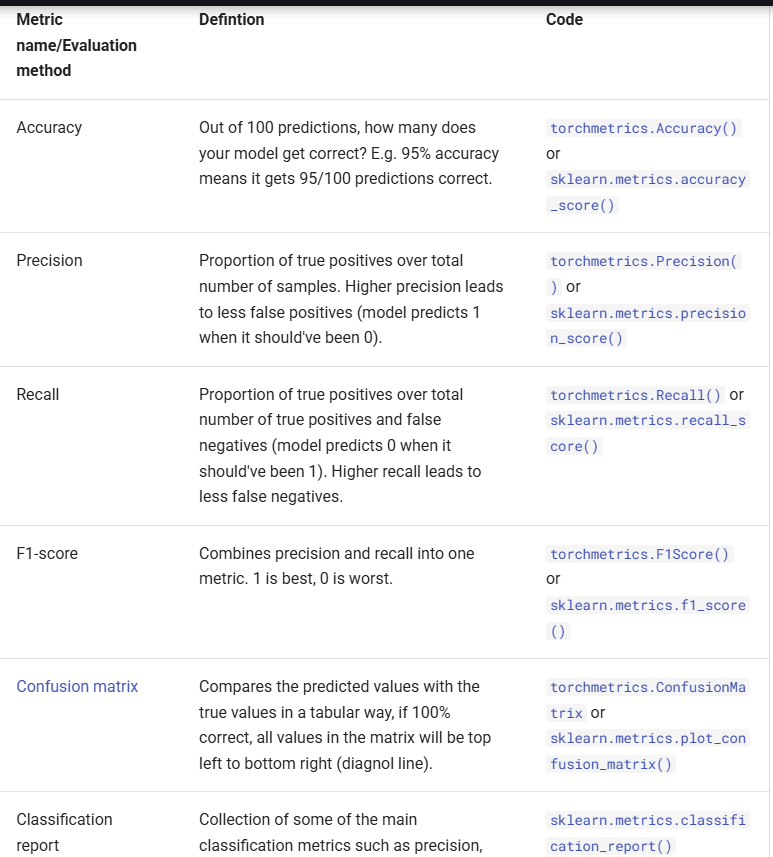

In [64]:
import torch

def evaluate_batch_predictions(model, data_loader, criterion, device='cuda', model_name="Model"):
    """
    Performs a forward pass on one batch of data, prints logits, probabilities,
    and computes optional loss and accuracy for debugging purposes.

    Args:
        model (torch.nn.Module): Trained model.
        data_loader (DataLoader): DataLoader (typically test or validation).
        criterion (loss function): e.g., torch.nn.CrossEntropyLoss().
        device (str): 'cuda' or 'cpu'.
        model_name (str): Name of the model (for display/logging).
    """
    model.eval()
    model.to(device)

    with torch.inference_mode():
        for x, y in data_loader:
            x, y = x.to(device), y.to(device)

            # 1. Forward pass
            y_logits = model(x)  # Shape: [batch_size, num_classes]

            # 2. Convert logits to probabilities
            y_pred_probs = torch.softmax(y_logits, dim=1)

            # 3. Print logits and probabilities for first few samples
            print(f"\n🔍 Debug Info - {model_name}")
            print("Raw Logits:\n", y_logits[:5])
            print("Probabilities:\n", y_pred_probs[:5])

            # 4. Get predicted class labels
            y_pred = y_pred_probs.argmax(dim=1)

            # 5. Compute loss and accuracy for the batch
            loss = criterion(y_logits, y)
            acc = (y_pred == y).sum().item() / len(y)

            print(f"Loss: {loss.item():.4f}, Accuracy: {acc:.4f}")
            break  # Only evaluate one batch



## fuctions for statistical output

In [62]:
def plot_training_statistics(train_stats, model_name):

    fig, axes = plt.subplots(2, figsize=(15,15))
    axes[0].plot(train_stats[f'{model_name}_Training_Loss'], label=f'{model_name}_Training_Loss')
    axes[0].plot(train_stats[f'{model_name}_Validation_Loss'], label=f'{model_name}_Validation_Loss')
    axes[1].plot(train_stats[f'{model_name}_Training_Acc'], label=f'{model_name}_Training_Acc')
    axes[1].plot(train_stats[f'{model_name}_Validation_Acc'], label=f'{model_name}_Validation_Acc')

    axes[0].set_xlabel("Number of Epochs"), axes[0].set_ylabel("Loss")
    axes[1].set_xlabel("Number of Epochs"), axes[1].set_ylabel("Accuracy in %")

    axes[0].legend(), axes[1].legend()

In [63]:
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from torchmetrics import ConfusionMatrix

def plot_confusion_matrix(model, data_loader, class_names, device='cuda', model_name="Model"):
    """
    Plots a confusion matrix heatmap for a given model and dataset.

    Args:
        model (torch.nn.Module): The trained model to evaluate.
        data_loader (DataLoader): DataLoader for validation or test data.
        class_names (list): List of class names (labels).
        device (str): Device to run the model on ('cuda' or 'cpu').
        model_name (str): Optional label for the plot title.
    """
    model.eval()
    model.to(device)

    num_classes = len(class_names)
    cm_total = torch.zeros((num_classes, num_classes), dtype=torch.int32)

    # Collect predictions and true labels
    true_labels = []
    predicted_labels = []

    with torch.inference_mode():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)

            # Update confusion matrix
            cm_total += ConfusionMatrix(num_classes=num_classes, task="multiclass")(preds.cpu(), labels.cpu())

            # Collect for optional use
            true_labels.extend(labels.cpu().numpy())
            predicted_labels.extend(preds.cpu().numpy())

    # Convert confusion matrix to NumPy array
    cm_numpy = cm_total.numpy()

    # Plot heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_numpy, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(f'Confusion Matrix Heatmap - {model_name}')
    plt.tight_layout()
    plt.show()


In [64]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from itertools import cycle
import torch

def plot_multiclass_roc(model, data_loader, class_names, device='cuda', model_name="Model"):
    """
    Plots multi-class ROC curves for a given model.

    Args:
        model (torch.nn.Module): Trained model.
        data_loader (DataLoader): Validation or test DataLoader.
        class_names (list): List of class names.
        device (str): 'cuda' or 'cpu'.
        model_name (str): Optional name to include in the plot title.
    """
    model.eval()
    model.to(device)

    all_labels = []
    all_probs = []

    with torch.inference_mode():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    # Binarize true labels and stack predicted probabilities
    all_labels = label_binarize(all_labels, classes=list(range(len(class_names))))
    all_probs = torch.tensor(all_probs).cpu().numpy()

    # Compute ROC curve and AUC for each class
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(all_labels[:, i], all_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Plot
    plt.figure(figsize=(10, 8))
    colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple', 'gold', 'deeppink'])

    for i, color in zip(range(len(class_names)), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label=f'ROC curve of class {class_names[i]} (area = {roc_auc[i]:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Multi-class ROC Curve - {model_name}')
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


In [68]:
import torch
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

def visualize_predictions(model, data_loader, class_names, device='cuda', model_name='Model', n_images=16):
    """
    Displays a grid of predictions vs ground truth labels from a DataLoader batch.

    Args:
        model (torch.nn.Module): Trained model for prediction.
        data_loader (DataLoader): DataLoader (usually validation or test).
        class_names (list): List of class names (e.g., ['glass', 'paper', ...]).
        device (str): Device to run the model on.
        model_name (str): Optional model name to show in the title.
        n_images (int): Number of images to display (must be a square like 4, 9, 16).
    """
    model.eval()
    model.to(device)

    rows = cols = int(n_images**0.5)

    with torch.inference_mode():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)

            plt.figure(figsize=(cols * 4, rows * 4))
            plt.suptitle(f"Predictions vs Labels - {model_name}", fontsize=16)
            plt.subplots_adjust(hspace=0.5)

            for i in range(min(n_images, len(images))):
                ax = plt.subplot(rows, cols, i + 1)
                img = make_grid(images[i], normalize=True).permute(1, 2, 0).cpu()
                plt.imshow(img)
                true_label = class_names[labels[i].item()]
                pred_label = class_names[preds[i].item()]
                plt.title(f"Label: {true_label}",fontsize=10)
                plt.xlabel(f"Predict: {pred_label}",fontsize=10)
                plt.axis("off")
            plt.tight_layout(rect=[0, 0, 1, 0.95])
            plt.show()
            break  # only show one batch


In [65]:
import random
import torch
import matplotlib.pyplot as plt
from torchvision.utils import make_grid
def visualize_predictions(model, test_dataset, classes, device='cuda',model_name='model'):
    
    # Assume:
    #  test_dataset is your ImageFolder-based dataset for testing
    #  test_loader  is your DataLoader for test_dataset (we’ll only use test_dataset.targets)
    #  model        is your trained model (e.g. base_densenet121)
    #  device       is "cuda" or "cpu"
    #  classes      is your class-names list: ['cardboard','glass','metal','paper','plastic','trash']
    
    model = model.to(device)
    model.eval()
    
    # 1) Build a mapping from class idx → all dataset indices
    class_to_indices = {i: [] for i in range(len(classes))}
    for idx, label in enumerate(test_dataset.targets):
        class_to_indices[label].append(idx)
    
    # 2) Randomly sample 6 indices per class
    samples_per_class = 6
    sampled_indices = []
    for cls, indices in class_to_indices.items():
        sampled = random.sample(indices, min(samples_per_class, len(indices)))
        sampled_indices.extend(sampled)
    
    # 3) Load those images as a batch
    #    We can index directly into test_dataset
    imgs, lbls = zip(*(test_dataset[i] for i in sampled_indices))
    imgs = torch.stack(imgs).to(device)      # shape [36,3,H,W]
    lbls = torch.tensor(lbls).to(device)     # shape [36]
    
    # 4) Predict
    with torch.inference_mode():
        logits = model(imgs)
        preds  = logits.argmax(dim=1)
    
    # 5) Plot a 6×6 grid
    n_classes = len(classes)
    n_cols = samples_per_class
    n_rows = n_classes
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*3, n_rows*3))
    plt.subplots_adjust(hspace=0.6, wspace=0.4)
    
    for row in range(n_rows):
        for col in range(n_cols):
            ax = axes[row, col]
            idx = row * n_cols + col
            img_tensor = imgs[idx].cpu()
            # Un-normalize if you normalized during preprocessing:
            img = img_tensor * torch.tensor([0.229,0.224,0.225]).view(3,1,1) \
                         + torch.tensor([0.485,0.456,0.406]).view(3,1,1)
            img = img.clamp(0,1)
            ax.imshow(img.permute(1,2,0))  # CHW → HWC
    
            true_lbl = classes[lbls[idx].item()]
            pred_lbl = classes[preds[idx].item()]
            ax.set_title(f"T:{true_lbl}\nP:{pred_lbl}", fontsize=12)
            ax.axis('off')
    
    plt.suptitle(f"6 Random Examples per Class with predict using model {model_name} for ", size=16)
    plt.show()


In [ ]:
"""
Input and output shapes of a computer vision model
We've got a big tensor of values (the image) leading to a single value for the target (the label).
Let's see the image shape.
"""
# What's the shape of the image?
images.shape

## Save Models

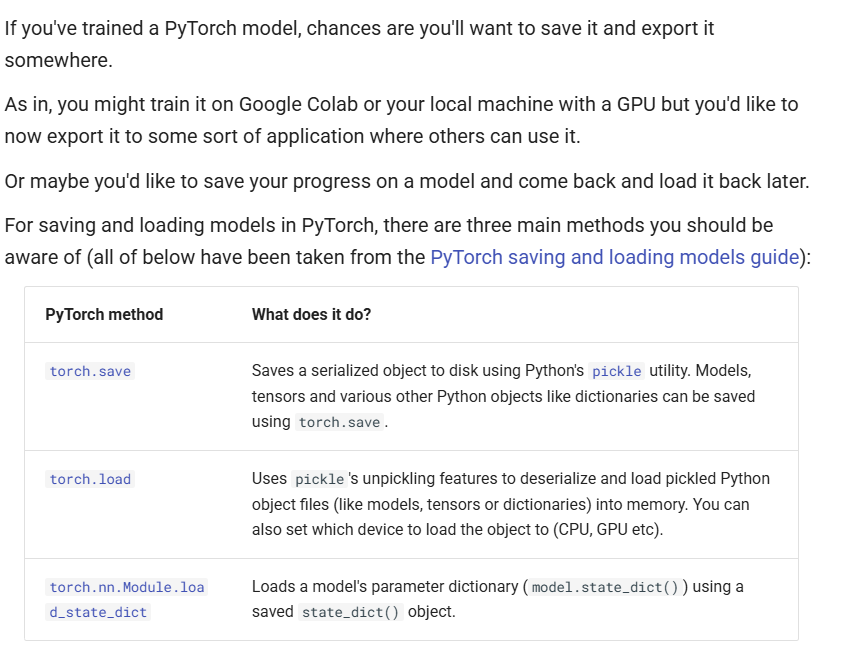

 **Saving a PyTorch model's state_dict()**
The recommended way for saving and loading a model for inference (making predictions) is by saving and loading a model's state_dict().

Let's see how we can do that in a few steps:

We'll create a directory for saving models to called models using Python's pathlib module.
We'll create a file path to save the model to.
We'll call torch.save(obj, f) where obj is the target model's state_dict() and f is the filename of where to save the model.
Note: It's common convention for PyTorch saved models or objects to end with .pt or .pth, like saved_model_01.pth.

In [66]:
from pathlib import Path
def save_model(model,MODEL_NAME):
    # 1. Create models directory
    MODEL_PATH = Path("models")
    MODEL_PATH.mkdir(parents=True, exist_ok=True)

    # 2. Create model save path
    #MODEL_NAME = "01_pytorch_workflow_model_0.pth"
    MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

    # 3. Save the model state dict
    print(f"Saving model to: {MODEL_SAVE_PATH}")
    torch.save(obj=model.state_dict(), # only saving the state_dict() only saves the models learned parameters
              f=MODEL_NAME)

In [ ]:
# Check the saved file path
!ls -l models/01_pytorch_workflow_model_0.pth

## Load  Saved Models

**Loading a saved PyTorch model's state_dict()**
Since we've now got a saved model state_dict() at models/01_pytorch_workflow_model_0.pth we can now load it in using torch.nn.Module.load_state_dict(torch.load(f)) where f is the filepath of our saved model state_dict().

Why call torch.load() inside torch.nn.Module.load_state_dict()?

Because we only saved the model's state_dict() which is a dictionary of learned parameters and not the entire model, we first have to load the state_dict() with torch.load() and then pass that state_dict() to a new instance of our model (which is a subclass of nn.Module).

Why not save the entire model?

Saving the entire model rather than just the state_dict() is more intuitive, however, to quote the PyTorch documentation (italics mine):

The disadvantage of this approach (saving the whole model) is that the serialized data is bound to the specific classes and the exact directory structure used when the model is saved...

Because of this, your code can break in various ways when used in other projects or after refactors.

So instead, we're using the flexible method of saving and loading just the state_dict(), which again is basically a dictionary of model parameters.

Let's test it out by creating another instance of LinearRegressionModel(), which is a subclass of torch.nn.Module and will hence have the in-built method load_state_dict().

In [ ]:
# Instantiate a new instance of our model (this will be instantiated with random weights)
loaded_model_0 = LinearRegressionModel()

# Load the state_dict of our saved model (this will update the new instance of our model with trained weights)
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

# Creating Models

## inception_v3

In [32]:
#call model arch
base_inception_v3=models.inception_v3(weights='IMAGENET1K_V1')


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth
100%|██████████| 104M/104M [00:00<00:00, 217MB/s] 


In [33]:
print(base_inception_v3)

Inception3(
  (Conv2d_1a_3x3): BasicConv2d(
    (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2a_3x3): BasicConv2d(
    (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2b_3x3): BasicConv2d(
    (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (maxpool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (Conv2d_3b_1x1): BasicConv2d(
    (conv): Conv2d(64, 80, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(80, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_4a_3x3): BasicConv2d(
    (conv): Conv2d(80, 192, kernel_size=(3, 3), stri

In [34]:
summary(base_inception_v3,input_size=(1,3, 299, 299))

Layer (type:depth-idx)                   Output Shape              Param #
Inception3                               [1, 1000]                 3,326,696
├─BasicConv2d: 1-1                       [1, 32, 149, 149]         --
│    └─Conv2d: 2-1                       [1, 32, 149, 149]         864
│    └─BatchNorm2d: 2-2                  [1, 32, 149, 149]         64
├─BasicConv2d: 1-2                       [1, 32, 147, 147]         --
│    └─Conv2d: 2-3                       [1, 32, 147, 147]         9,216
│    └─BatchNorm2d: 2-4                  [1, 32, 147, 147]         64
├─BasicConv2d: 1-3                       [1, 64, 147, 147]         --
│    └─Conv2d: 2-5                       [1, 64, 147, 147]         18,432
│    └─BatchNorm2d: 2-6                  [1, 64, 147, 147]         128
├─MaxPool2d: 1-4                         [1, 64, 73, 73]           --
├─BasicConv2d: 1-5                       [1, 80, 73, 73]           --
│    └─Conv2d: 2-7                       [1, 80, 73, 73]           5,

In [35]:
#change classification part to suitable with my case and replace number of classes from 1000 ---> to 6
base_inception_v3.fc = nn.Linear(base_inception_v3.fc.in_features,6)

In [36]:
print(base_inception_v3)

Inception3(
  (Conv2d_1a_3x3): BasicConv2d(
    (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2a_3x3): BasicConv2d(
    (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2b_3x3): BasicConv2d(
    (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (maxpool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (Conv2d_3b_1x1): BasicConv2d(
    (conv): Conv2d(64, 80, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(80, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_4a_3x3): BasicConv2d(
    (conv): Conv2d(80, 192, kernel_size=(3, 3), stri

In [37]:
for name, module in base_inception_v3.named_children():
    print(name, module)

Conv2d_1a_3x3 BasicConv2d(
  (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
  (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
)
Conv2d_2a_3x3 BasicConv2d(
  (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
  (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
)
Conv2d_2b_3x3 BasicConv2d(
  (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
)
maxpool1 MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
Conv2d_3b_1x1 BasicConv2d(
  (conv): Conv2d(64, 80, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn): BatchNorm2d(80, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
)
Conv2d_4a_3x3 BasicConv2d(
  (conv): Conv2d(80, 192, kernel_size=(3, 3), stride=(1, 1), bias=False)
  (bn): BatchNorm2d(192, eps=0.001, momentum=

In [38]:
for name, module in base_inception_v3.named_modules():
    print(name, module)

 Inception3(
  (Conv2d_1a_3x3): BasicConv2d(
    (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2a_3x3): BasicConv2d(
    (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2b_3x3): BasicConv2d(
    (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (maxpool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (Conv2d_3b_1x1): BasicConv2d(
    (conv): Conv2d(64, 80, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(80, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_4a_3x3): BasicConv2d(
    (conv): Conv2d(80, 192, kernel_size=(3, 3), str

In [39]:
# let's visualize layer names and layer indices to see how many layers
# we should freeze:
for name, param in base_inception_v3.named_parameters():
    print(name, param.shape)

Conv2d_1a_3x3.conv.weight torch.Size([32, 3, 3, 3])
Conv2d_1a_3x3.bn.weight torch.Size([32])
Conv2d_1a_3x3.bn.bias torch.Size([32])
Conv2d_2a_3x3.conv.weight torch.Size([32, 32, 3, 3])
Conv2d_2a_3x3.bn.weight torch.Size([32])
Conv2d_2a_3x3.bn.bias torch.Size([32])
Conv2d_2b_3x3.conv.weight torch.Size([64, 32, 3, 3])
Conv2d_2b_3x3.bn.weight torch.Size([64])
Conv2d_2b_3x3.bn.bias torch.Size([64])
Conv2d_3b_1x1.conv.weight torch.Size([80, 64, 1, 1])
Conv2d_3b_1x1.bn.weight torch.Size([80])
Conv2d_3b_1x1.bn.bias torch.Size([80])
Conv2d_4a_3x3.conv.weight torch.Size([192, 80, 3, 3])
Conv2d_4a_3x3.bn.weight torch.Size([192])
Conv2d_4a_3x3.bn.bias torch.Size([192])
Mixed_5b.branch1x1.conv.weight torch.Size([64, 192, 1, 1])
Mixed_5b.branch1x1.bn.weight torch.Size([64])
Mixed_5b.branch1x1.bn.bias torch.Size([64])
Mixed_5b.branch5x5_1.conv.weight torch.Size([48, 192, 1, 1])
Mixed_5b.branch5x5_1.bn.weight torch.Size([48])
Mixed_5b.branch5x5_1.bn.bias torch.Size([48])
Mixed_5b.branch5x5_2.conv.wei

In [40]:
## 1) Freeze all parameters
for param in base_inception_v3.parameters():
    param.requires_grad = False

# 2) Unfreeze the final classifier for finetuning classifier
for param in base_inception_v3.fc.parameters():
    param.requires_grad = True

# 3) Unfreeze Mixed_7b and Mixed_7c blocks for finetuning conv_features implement in second try
"""for name, module in base_inception_v3.named_children():
    if name in ('Mixed_7b', 'Mixed_7c'):
        for param in module.parameters():
            param.requires_grad = True"""

"for name, module in base_inception_v3.named_children():\n    if name in ('Mixed_7b', 'Mixed_7c'):\n        for param in module.parameters():\n            param.requires_grad = True"

In [102]:
trainable = [name for name, p in base_inception_v3.named_parameters() if p.requires_grad]
print("Trainable parameters:")
print("\n".join(trainable))

Trainable parameters:
fc.weight
fc.bias


# Densenet121

In [20]:
base_densenet121= models.densenet121(weights='IMAGENET1K_V1')

In [3]:
print(base_densenet121_tuned)

DenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu

In [107]:
summary(base_densenet121_tuned, input_size=( 1,3, 224, 224))

Layer (type:depth-idx)                   Output Shape              Param #
DenseNet                                 [1, 1000]                 --
├─Sequential: 1-1                        [1, 1024, 7, 7]           --
│    └─Conv2d: 2-1                       [1, 64, 112, 112]         9,408
│    └─BatchNorm2d: 2-2                  [1, 64, 112, 112]         128
│    └─ReLU: 2-3                         [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-4                    [1, 64, 56, 56]           --
│    └─_DenseBlock: 2-5                  [1, 256, 56, 56]          --
│    │    └─_DenseLayer: 3-1             [1, 32, 56, 56]           45,440
│    │    └─_DenseLayer: 3-2             [1, 32, 56, 56]           49,600
│    │    └─_DenseLayer: 3-3             [1, 32, 56, 56]           53,760
│    │    └─_DenseLayer: 3-4             [1, 32, 56, 56]           57,920
│    │    └─_DenseLayer: 3-5             [1, 32, 56, 56]           62,080
│    │    └─_DenseLayer: 3-6             [1, 32, 56, 56]     

In [21]:
#change classification part to suitable with my case and replace number of classes from 1000 ---> to 6
base_densenet121.classifier= nn.Linear(base_densenet121.classifier.in_features,6)

In [ ]:
# make fine_tuning on classification layer
num_ftrs = base_densenet121.classifier.in_features
        base_densenet121.classifier = nn.Sequential(
            nn.Linear(num_ftrs, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate/2),
            nn.Linear(256, num_classes)
        )

In [46]:
# let's visualize layer names and layer indices to see how many layers
# we should freeze:
for name, param in base_densenet121.named_parameters():
    print(name, param.shape)

features.conv0.weight torch.Size([64, 3, 7, 7])
features.norm0.weight torch.Size([64])
features.norm0.bias torch.Size([64])
features.denseblock1.denselayer1.norm1.weight torch.Size([64])
features.denseblock1.denselayer1.norm1.bias torch.Size([64])
features.denseblock1.denselayer1.conv1.weight torch.Size([128, 64, 1, 1])
features.denseblock1.denselayer1.norm2.weight torch.Size([128])
features.denseblock1.denselayer1.norm2.bias torch.Size([128])
features.denseblock1.denselayer1.conv2.weight torch.Size([32, 128, 3, 3])
features.denseblock1.denselayer2.norm1.weight torch.Size([96])
features.denseblock1.denselayer2.norm1.bias torch.Size([96])
features.denseblock1.denselayer2.conv1.weight torch.Size([128, 96, 1, 1])
features.denseblock1.denselayer2.norm2.weight torch.Size([128])
features.denseblock1.denselayer2.norm2.bias torch.Size([128])
features.denseblock1.denselayer2.conv2.weight torch.Size([32, 128, 3, 3])
features.denseblock1.denselayer3.norm1.weight torch.Size([128])
features.densebl

In [129]:

# 2) Freeze all backbone parameters
for param in base_densenet121_tuned.parameters():
    param.requires_grad = False
for param in base_densenet121_tuned.classifier.parameters():
   param.requires_grad = True
    
# 3) Grab the number of features coming out of the last conv layer
#    DenseNet121 normally does: features → relu → adaptive_pool → flatten → classifier
num_ftrs = base_densenet121_tuned.classifier.in_features

# 4) Build a new classifier head
#    - AdaptiveAvgPool2d(1) is Global Average Pooling
#    - Flatten out the [B, C, 1, 1] → [B, C]
#    - Linear → ReLU → Dropout (optional) → final Linear to 6 classes
base_densenet121_tuned.classifier = nn.Sequential(
    nn.Linear(num_ftrs, 256),      # Dense layer
    nn.ReLU(inplace=True),            # optional, helps regularize
    nn.Linear(256, 6)              # 6 trash classes
)



In [130]:
# 5) Move to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
base_densenet121_tuned= base_densenet121_tuned.to(device)

# 6) Now only the new head’s parameters are trainable:
trainable_params = [p for p in base_densenet121_tuned.parameters() if p.requires_grad]
print(f"Number of trainable parameters: {sum(p.numel() for p in trainable_params)}")




Number of trainable parameters: 263942


In [131]:
trainable = [name for name, p in base_densenet121_tuned.named_parameters() if p.requires_grad]
print("Trainable parameters:")
print("\n".join(trainable))

Trainable parameters:
classifier.0.weight
classifier.0.bias
classifier.2.weight
classifier.2.bias


In [22]:
## 1) Freeze all parameters
for param in base_densenet121.parameters():
    param.requires_grad = True

# 2) Unfreeze the final classifier for finetuning classifier
#for param in base_densenet121.classifier.parameters():
 #   param.requires_grad = True

# 3) Unfreeze Mixed_7b and Mixed_7c blocks for finetuning conv_features implement in second try
"""for name, module in base_densenet121.named_children():
    if name in ('Mixed_7b', 'Mixed_7c'):
        for param in module.parameters():
            param.requires_grad = True"""

"for name, module in base_densenet121.named_children():\n    if name in ('Mixed_7b', 'Mixed_7c'):\n        for param in module.parameters():\n            param.requires_grad = True"

# MobileNet_V2

In [6]:
base_mobilenet_v2 = models.mobilenet_v2(weights='IMAGENET1K_V1')

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth
100%|██████████| 13.6M/13.6M [00:00<00:00, 108MB/s] 


In [18]:
print("base_mobilenet_v2=",base_mobilenet_v2)

base_mobilenet_v2= MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): B

In [19]:
summary(base_mobilenet_v2, input_size=( 1,3, 224, 224))

Layer (type:depth-idx)                             Output Shape              Param #
MobileNetV2                                        [1, 1000]                 --
├─Sequential: 1-1                                  [1, 1280, 7, 7]           --
│    └─Conv2dNormActivation: 2-1                   [1, 32, 112, 112]         --
│    │    └─Conv2d: 3-1                            [1, 32, 112, 112]         864
│    │    └─BatchNorm2d: 3-2                       [1, 32, 112, 112]         64
│    │    └─ReLU6: 3-3                             [1, 32, 112, 112]         --
│    └─InvertedResidual: 2-2                       [1, 16, 112, 112]         --
│    │    └─Sequential: 3-4                        [1, 16, 112, 112]         896
│    └─InvertedResidual: 2-3                       [1, 24, 56, 56]           --
│    │    └─Sequential: 3-5                        [1, 24, 56, 56]           5,136
│    └─InvertedResidual: 2-4                       [1, 24, 56, 56]           --
│    │    └─Sequential: 3-6   

In [7]:
#change classification part to suitable with my case and replace number of classes from 1000 ---> to 6
base_mobilenet_v2.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=False),
    nn.Linear(in_features=1280, out_features=6, bias=True)
)

In [21]:
# let's visualize layer names and layer indices to see how many layers
# we should freeze:
for name, param in base_mobilenet_v2.named_parameters():
    print(name, param.shape)

features.0.0.weight torch.Size([32, 3, 3, 3])
features.0.1.weight torch.Size([32])
features.0.1.bias torch.Size([32])
features.1.conv.0.0.weight torch.Size([32, 1, 3, 3])
features.1.conv.0.1.weight torch.Size([32])
features.1.conv.0.1.bias torch.Size([32])
features.1.conv.1.weight torch.Size([16, 32, 1, 1])
features.1.conv.2.weight torch.Size([16])
features.1.conv.2.bias torch.Size([16])
features.2.conv.0.0.weight torch.Size([96, 16, 1, 1])
features.2.conv.0.1.weight torch.Size([96])
features.2.conv.0.1.bias torch.Size([96])
features.2.conv.1.0.weight torch.Size([96, 1, 3, 3])
features.2.conv.1.1.weight torch.Size([96])
features.2.conv.1.1.bias torch.Size([96])
features.2.conv.2.weight torch.Size([24, 96, 1, 1])
features.2.conv.3.weight torch.Size([24])
features.2.conv.3.bias torch.Size([24])
features.3.conv.0.0.weight torch.Size([144, 24, 1, 1])
features.3.conv.0.1.weight torch.Size([144])
features.3.conv.0.1.bias torch.Size([144])
features.3.conv.1.0.weight torch.Size([144, 1, 3, 3])

In [22]:
## 1) Freeze all parameters
for param in base_mobilenet_v2.parameters():
    param.requires_grad = False

# 2) Unfreeze the final classifier for finetuning classifier
for param in base_mobilenet_v2.classifier.parameters():
    param.requires_grad = True

# 3) Unfreeze Mixed_7b and Mixed_7c blocks for finetuning conv_features implement in second try
"""for name, module in base_mobilenet_v2.named_children():
    if name in ('Mixed_7b', 'Mixed_7c'):
        for param in module.parameters():
            param.requires_grad = True"""

"for name, module in base_mobilenet_v2.named_children():\n    if name in ('Mixed_7b', 'Mixed_7c'):\n        for param in module.parameters():\n            param.requires_grad = True"

In [23]:
trainable = [name for name, p in base_mobilenet_v2.named_parameters() if p.requires_grad]
print("Trainable parameters:")
print("\n".join(trainable))

Trainable parameters:
classifier.1.weight
classifier.1.bias


## Resnet50

In [24]:
base_resnet50 = models.resnet50(weights='IMAGENET1K_V1')

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 140MB/s]


In [25]:
print("base_mobilenet_v2=",base_resnet50)

base_mobilenet_v2= ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=

In [26]:
summary(base_resnet50, input_size=( 1,3, 224, 224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 1000]                 --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 256, 56, 56]          --
│    └─Bottleneck: 2-1                   [1, 256, 56, 56]          --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           4,096
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]           --
│ 

In [27]:
#change classification part to suitable with my case and replace number of classes from 1000 ---> to 6
base_resnet50.fc = nn.Linear(base_resnet50.fc.in_features,6)

In [28]:
# let's visualize layer names and layer indices to see how many layers
# we should freeze:
for name, param in base_resnet50.named_parameters():
    print(name, param.shape)

conv1.weight torch.Size([64, 3, 7, 7])
bn1.weight torch.Size([64])
bn1.bias torch.Size([64])
layer1.0.conv1.weight torch.Size([64, 64, 1, 1])
layer1.0.bn1.weight torch.Size([64])
layer1.0.bn1.bias torch.Size([64])
layer1.0.conv2.weight torch.Size([64, 64, 3, 3])
layer1.0.bn2.weight torch.Size([64])
layer1.0.bn2.bias torch.Size([64])
layer1.0.conv3.weight torch.Size([256, 64, 1, 1])
layer1.0.bn3.weight torch.Size([256])
layer1.0.bn3.bias torch.Size([256])
layer1.0.downsample.0.weight torch.Size([256, 64, 1, 1])
layer1.0.downsample.1.weight torch.Size([256])
layer1.0.downsample.1.bias torch.Size([256])
layer1.1.conv1.weight torch.Size([64, 256, 1, 1])
layer1.1.bn1.weight torch.Size([64])
layer1.1.bn1.bias torch.Size([64])
layer1.1.conv2.weight torch.Size([64, 64, 3, 3])
layer1.1.bn2.weight torch.Size([64])
layer1.1.bn2.bias torch.Size([64])
layer1.1.conv3.weight torch.Size([256, 64, 1, 1])
layer1.1.bn3.weight torch.Size([256])
layer1.1.bn3.bias torch.Size([256])
layer1.2.conv1.weight tor

In [29]:
## 1) Freeze all parameters
for param in base_resnet50.parameters():
    param.requires_grad = False

# 2) Unfreeze the final classifier for finetuning classifier
for param in base_resnet50.fc.parameters():
    param.requires_grad = True

# 3) Unfreeze Mixed_7b and Mixed_7c blocks for finetuning conv_features implement in second try
"""for name, module in base_resnet50.named_children():
    if name in ('Mixed_7b', 'Mixed_7c'):
        for param in module.parameters():
            param.requires_grad = True"""

"for name, module in base_resnet50.named_children():\n    if name in ('Mixed_7b', 'Mixed_7c'):\n        for param in module.parameters():\n            param.requires_grad = True"

In [30]:
trainable = [name for name, p in base_resnet50.named_parameters() if p.requires_grad]
print("Trainable parameters:")
print("\n".join(trainable))

Trainable parameters:
fc.weight
fc.bias


# Training&Evaluation

In [ ]:
#class_names=["cardboard","glass","metal","paper","plastic","trash"]

In [ ]:
class_names= ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

In [99]:
import torch
#cal weights for train data 
class_counts = {
   'cardboard': 15.93,
   'glass': 19.84,
   'metal': 16.23,
   'paper': 23.5,
   'plastic': 19.05, 
   'trash': 5.44,
  
 }


# Convert to weights: inverse frequency
total = sum(class_counts.values())
print(class_counts.values())
weights = [total / v for v in class_counts.values()]
weights = torch.tensor(weights, dtype=torch.float32)

# Normalize (optional)
weights_train = weights / weights.sum()

print("Class Weights:", weights_train)
#weight=weights_train.to(device)

dict_values([15.93, 19.84, 16.23, 23.5, 19.05, 5.44])
Class Weights: tensor([0.1384, 0.1111, 0.1358, 0.0938, 0.1157, 0.4052])


In [12]:
#to overcome on un balance
criterion=torch.nn.CrossEntropyLoss()
epochs=15

In [ ]:
import os

# Print the current working directory
print(os.getcwd())

# Check if the file exists in the current directory
print(os.listdir("/kaggle/working/"))

/kaggle/working
['modeldensenet121_10_TACO_epoches.pth', 'taco-dataset-separated-images', '.virtual_documents', 'densenet121.pt']


In [ ]:
# Create a downloadable link
from IPython.display import FileLink
FileLink("/kaggle/working/modeldensenet121_10_TACO_epoches.pth")

## train_mobilenet_v2

In [54]:
train_loader, val_loader,test_loader, class_names, input_size=prepare_dataloaders(data_dir,data_dir_test, "base_mobilenet_v2", batch_size=16)


Train samples: 14147, Batches: 885
Validation samples: 1771, Batches: 111
Test samples: 253, Batches: 16


In [55]:
print("train_loader=",train_loader)
print("val_loader=",val_loader)
print("test_loader=",test_loader)
print("class_names=",class_names)
print("input_size=",input_size)

train_loader= <torch.utils.data.dataloader.DataLoader object at 0x7d262d4c9490>
val_loader= <torch.utils.data.dataloader.DataLoader object at 0x7d262d665e10>
test_loader= <torch.utils.data.dataloader.DataLoader object at 0x7d262d3a17d0>
class_names= ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
input_size= 224


In [ ]:
#Now create your optimizer over only those trainable parameters:
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, base_mobilenet_v2.parameters()),
    lr=1e-4,  # often lower LR for fine‑tuning
)

In [ ]:
optimizer_mobilenetv2=optim.SGD(filter(lambda p: p.requires_grad,base_mobilenet_v2.parameters()), lr=0.001,momentum=0.9 )


In [ ]:
#trainning
history_mobilenet_v2=fit_model(base_mobilenet_v2 , "base_mobilenet_v2", train_loader, val_loader,criterion, optimizer_mobilenetv2,epochs, device)

In [ ]:
evaluate_batch_predictions(
    model=base_mobilenet_v2,
    data_loader=test_loader,
    criterion=criterion,
    device=device,
    model_name="mobilenet_v2"
)

In [ ]:
plot_training_statistics(history_mobilenet_v2, 'mobilenet_v2')

In [ ]:
plot_confusion_matrix(base_mobilenet_v2, test_loader, class_names, device='cuda', model_name="mobilenet_v2")

In [ ]:
plot_multiclass_roc(base_mobilenet_v2, test_loader, class_names, device='cuda', model_name="mobilenet_v2")

In [ ]:
visualize_predictions(base_mobilenet_v2, test_loader, class_names, device='cuda', model_name='mobilenet_v2', n_images=16)

In [ ]:
save_model(base_mobilenet_v2,"base_mobilenet_v2_15_epoches.pth")

## train Densenet121

In [13]:
data_dir_for_train="/kaggle/working/Trashfolder/split_Trash_dataset_augmented_classify_train_val"
data_dir_for_test_val="/kaggle/working/Trashfolder/split_Trashdataset_original_without_aug"

In [23]:
train_loader, val_loader,test_loader, class_names, input_size=prepare_dataloaders(data_dir_for_train,data_dir_for_test_val, "base_densenet121", batch_size=16)

Train samples: 14147, Batches: 885
Validation samples: 253, Batches: 16
Test samples: 253, Batches: 16


In [24]:
batch_imgs_val, batch_lbls_val = next(iter(val_loader))
print("Val batch labels:", batch_lbls_val.tolist())

Val batch labels: [1, 4, 5, 3, 3, 5, 4, 5, 3, 2, 2, 0, 4, 3, 2, 2]


In [118]:
print("train_loader=",train_loader)
print("val_loader=",val_loader)
print("test_loader=",test_loader)
print("class_names=",class_names)
print("input_size=",input_size)

train_loader= <torch.utils.data.dataloader.DataLoader object at 0x7b414816ad90>
val_loader= <torch.utils.data.dataloader.DataLoader object at 0x7b41941f06d0>
test_loader= <torch.utils.data.dataloader.DataLoader object at 0x7b414816ad10>
class_names= ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
input_size= 224


In [25]:
#Now create your optimizer over only those trainable parameters:
optimizer = torch.optim.Adam(
    base_densenet121.parameters(),
   lr=0.001
    
)
#lr=1e-4,  # often lower LR for fine‑tuning

In [91]:
optimizer_densenet121_SGD=optim.SGD( filter(lambda p: p.requires_grad,base_densenet121_tuned.parameters()), lr=0.001,momentum=0.9 )
epochs=15

In [16]:
def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs
def calculate_accuracy(y_pred, y):
    top_pred = y_pred.argmax(1, keepdim = True)
    correct = top_pred.eq(y.view_as(top_pred)).sum()
    acc = correct.float() / y.shape[0]
    return acc

In [17]:
def train(model, iterator, optimizer, criterion):
    
    epoch_loss = 0
    epoch_acc = 0
    model = model.cuda()
    model.train()
    
    for i,data in enumerate(tqdm(iterator)):
        
        x = data[0].cuda()
        y = data[1].cuda()
        
        optimizer.zero_grad()
         #,hidden   for inceptionv3    
        y_pred = model(x)
        
        loss = criterion(y_pred, y)
        
        acc = calculate_accuracy(y_pred, y)
        
        loss.backward()
        
        optimizer.step()
        
        epoch_loss += loss.item()
        epoch_acc += acc.item()
        
    return epoch_loss / len(iterator), epoch_acc / len(iterator)
def evaluate(model, iterator, criterion):
    
    epoch_loss = 0
    epoch_acc = 0
    
    model.eval()
    
    with torch.no_grad():
        
        for i,data in enumerate(tqdm(iterator)):

            x = data[0].cuda()
            y = data[1].cuda()
        
            y_pred = model(x)

            loss = criterion(y_pred, y)

            acc = calculate_accuracy(y_pred, y)

            epoch_loss += loss.item()
            epoch_acc += acc.item()
        
    return epoch_loss / len(iterator), epoch_acc / len(iterator)

In [18]:
def fit_model(model, model_name, train_iterator, valid_iterator, optimizer, loss_criterion, epochs):
    """ Fits a dataset to model"""
    best_valid_loss = float('inf')
    
    train_losses = []
    valid_losses = []
    train_accs = []
    valid_accs = []
    start_time1 = time.time()
    for epoch in range(epochs):
    
        start_time = time.time()
    
        train_loss, train_acc = train(model, train_iterator, optimizer, loss_criterion)
        valid_loss, valid_acc = evaluate(model, valid_iterator, loss_criterion)
        
        train_losses.append(train_loss)
        valid_losses.append(valid_loss)
        train_accs.append(train_acc*100)
        valid_accs.append(valid_acc*100)
    
        if valid_loss < best_valid_loss:
            best_valid_loss = valid_loss
            torch.save(model.state_dict(), f'{model_name}.pt')
    
        end_time = time.time()

        epoch_mins, epoch_secs = epoch_time(start_time, end_time)
    
        print(f'Epoch: {epoch+1:02} | Epoch Time: {epoch_mins}m {epoch_secs}s')
        print(f'\tTrain Loss: {train_loss:.3f} | Train Acc: {train_acc*100:.2f}%')
        print(f'\t Val. Loss: {valid_loss:.3f} |  Val. Acc: {valid_acc*100:.2f}%')
    end_time1 = time.time() 
    Total_mins, Total_secs = epoch_time(start_time1, end_time1)
    print(f"\n Total Time :{Total_mins}m {Total_secs}s")   
    return pd.DataFrame({f'{model_name}_Training_Loss':train_losses, 
                        f'{model_name}_Training_Acc':train_accs, 
                        f'{model_name}_Validation_Loss':valid_losses, 
                        f'{model_name}_Validation_Acc':valid_accs})

In [26]:
history_densenet121_sec=fit_model(base_densenet121 , "base_densenet121", train_loader, val_loader, optimizer ,criterion,epochs)

100%|██████████| 16/16 [00:01<00:00, 12.75it/s]


Epoch: 01 | Epoch Time: 2m 48s
	Train Loss: 1.024 | Train Acc: 61.58%
	 Val. Loss: 0.873 |  Val. Acc: 71.12%


100%|██████████| 16/16 [00:01<00:00, 12.80it/s]


Epoch: 02 | Epoch Time: 2m 46s
	Train Loss: 0.735 | Train Acc: 73.25%
	 Val. Loss: 0.517 |  Val. Acc: 85.07%


100%|██████████| 16/16 [00:01<00:00, 12.71it/s]


...

Epoch: 13 | Epoch Time: 2m 43s
	Train Loss: 0.262 | Train Acc: 90.84%
	 Val. Loss: 0.539 |  Val. Acc: 86.84%


100%|██████████| 16/16 [00:01<00:00, 12.97it/s]


Epoch: 14 | Epoch Time: 2m 42s
	Train Loss: 0.251 | Train Acc: 91.46%
	 Val. Loss: 0.508 |  Val. Acc: 89.36%


100%|██████████| 16/16 [00:01<00:00, 13.09it/s]

Epoch: 15 | Epoch Time: 2m 42s
	Train Loss: 0.241 | Train Acc: 91.50%
	 Val. Loss: 0.479 |  Val. Acc: 88.19%

 Total Time :41m 13s


In [19]:
history_densenet121_sec=fit_model(base_densenet121 , "base_densenet121", train_loader, val_loader, optimizer ,criterion,epochs)

100%|██████████| 8/8 [00:01<00:00,  5.59it/s]


Epoch: 01 | Epoch Time: 2m 34s
	Train Loss: 1.680 | Train Acc: 29.02%
	 Val. Loss: 1.551 |  Val. Acc: 40.95%


100%|██████████| 8/8 [00:01<00:00,  5.78it/s]


Epoch: 02 | Epoch Time: 2m 52s
	Train Loss: 1.492 | Train Acc: 46.84%
	 Val. Loss: 1.383 |  Val. Acc: 55.72%


100%|██████████| 8/8 [00:01<00:00,  5.75it/s]


...

Epoch: 13 | Epoch Time: 2m 52s
	Train Loss: 0.770 | Train Acc: 75.86%
	 Val. Loss: 0.696 |  Val. Acc: 79.88%


100%|██████████| 8/8 [00:01<00:00,  5.73it/s]


Epoch: 14 | Epoch Time: 2m 52s
	Train Loss: 0.743 | Train Acc: 76.42%
	 Val. Loss: 0.661 |  Val. Acc: 80.58%


100%|██████████| 8/8 [00:01<00:00,  5.39it/s]


Epoch: 15 | Epoch Time: 2m 52s
	Train Loss: 0.715 | Train Acc: 77.33%
	 Val. Loss: 0.643 |  Val. Acc: 79.18%

 Total Time :42m 52s


In [ ]:
train_densenet121 = fit_model(net2, 'densenet121', train_loader, val_loader, optimizer, criterion, epochs=10)

In [106]:
#trainning
history_densenet121=fit_model(base_densenet121 , "base_densenet121", train_loader, val_loader, optimizer ,criterion,epochs)

100%|██████████| 56/56 [00:06<00:00,  8.42it/s]


Epoch: 01 | Epoch Time: 2m 33s
	Train Loss: 0.280 | Train Acc: 89.99%
	 Val. Loss: 0.336 |  Val. Acc: 90.86%


100%|██████████| 56/56 [00:06<00:00,  8.50it/s]


Epoch: 02 | Epoch Time: 2m 33s
	Train Loss: 0.177 | Train Acc: 93.78%
	 Val. Loss: 0.368 |  Val. Acc: 91.59%


100%|██████████| 56/56 [00:06<00:00,  8.45it/s]


...

Epoch: 13 | Epoch Time: 2m 33s
	Train Loss: 0.092 | Train Acc: 96.87%
	 Val. Loss: 0.342 |  Val. Acc: 94.31%


100%|██████████| 56/56 [00:06<00:00,  8.40it/s]


Epoch: 14 | Epoch Time: 2m 33s
	Train Loss: 0.086 | Train Acc: 96.86%
	 Val. Loss: 0.304 |  Val. Acc: 94.42%


100%|██████████| 56/56 [00:06<00:00,  8.45it/s]

Epoch: 15 | Epoch Time: 2m 33s
	Train Loss: 0.067 | Train Acc: 97.69%
	 Val. Loss: 0.293 |  Val. Acc: 94.42%


In [142]:
history_densenet121_16_SGS=fit_model(base_densenet121 , "base_densenet121", train_loader, val_loader, optimizer ,criterion,epochs)

100%|██████████| 111/111 [00:06<00:00, 17.30it/s]


Epoch: 01 | Epoch Time: 2m 32s
	Train Loss: 0.544 | Train Acc: 80.51%
	 Val. Loss: 0.312 |  Val. Acc: 88.77%


100%|██████████| 111/111 [00:06<00:00, 17.40it/s]


Epoch: 02 | Epoch Time: 2m 33s
	Train Loss: 0.278 | Train Acc: 90.33%
	 Val. Loss: 0.258 |  Val. Acc: 91.50%


100%|██████████| 111/111 [00:06<00:00, 16.53it/s]


...

Epoch: 13 | Epoch Time: 2m 33s
	Train Loss: 0.075 | Train Acc: 97.32%
	 Val. Loss: 0.193 |  Val. Acc: 94.26%


100%|██████████| 111/111 [00:06<00:00, 17.08it/s]


Epoch: 14 | Epoch Time: 2m 33s
	Train Loss: 0.069 | Train Acc: 97.46%
	 Val. Loss: 0.203 |  Val. Acc: 94.54%


100%|██████████| 111/111 [00:06<00:00, 16.71it/s]

Epoch: 15 | Epoch Time: 2m 34s
	Train Loss: 0.074 | Train Acc: 97.35%
	 Val. Loss: 0.167 |  Val. Acc: 95.66%


In [143]:
evaluate_batch_predictions(
    model=base_densenet121,
    data_loader=test_loader,
    criterion=criterion,
    device=device,
    model_name="densenet121"
)


🔍 Debug Info - densenet121
Raw Logits:
 tensor([[ 19.7049,  -3.3232, -13.9878,   0.2293,   2.5349,  -3.8250],
        [ 20.1327,  -5.0002,  -2.3249,   1.8172,  -5.9724,  -6.9148],
        [ 18.6309,  -0.5895,  -0.8165,  -4.3205,  -0.5834,  -8.2680],
        [  9.9999,  -5.7189,   1.7607,  -0.8153,   0.8477,  -4.9188],
        [ 10.5078,  -2.9082,  -6.9285,   6.3731,  -2.3806,  -3.6812]],
       device='cuda:0')
Probabilities:
 tensor([[1.0000e+00, 9.9779e-11, 2.3306e-15, 3.4825e-09, 3.4930e-08, 6.0410e-11],
        [1.0000e+00, 1.2160e-11, 1.7651e-10, 1.1109e-08, 4.5994e-12, 1.7923e-12],
        [1.0000e+00, 4.4946e-09, 3.5819e-09, 1.0773e-10, 4.5221e-09, 2.0796e-12],
        [9.9961e-01, 1.4902e-07, 2.6399e-04, 2.0082e-05, 1.0594e-04, 3.3168e-07],
        [9.8424e-01, 1.4676e-06, 2.6340e-08, 1.5756e-02, 2.4875e-06, 6.7751e-07]],
       device='cuda:0')
Loss: 0.0268, Accuracy: 1.0000


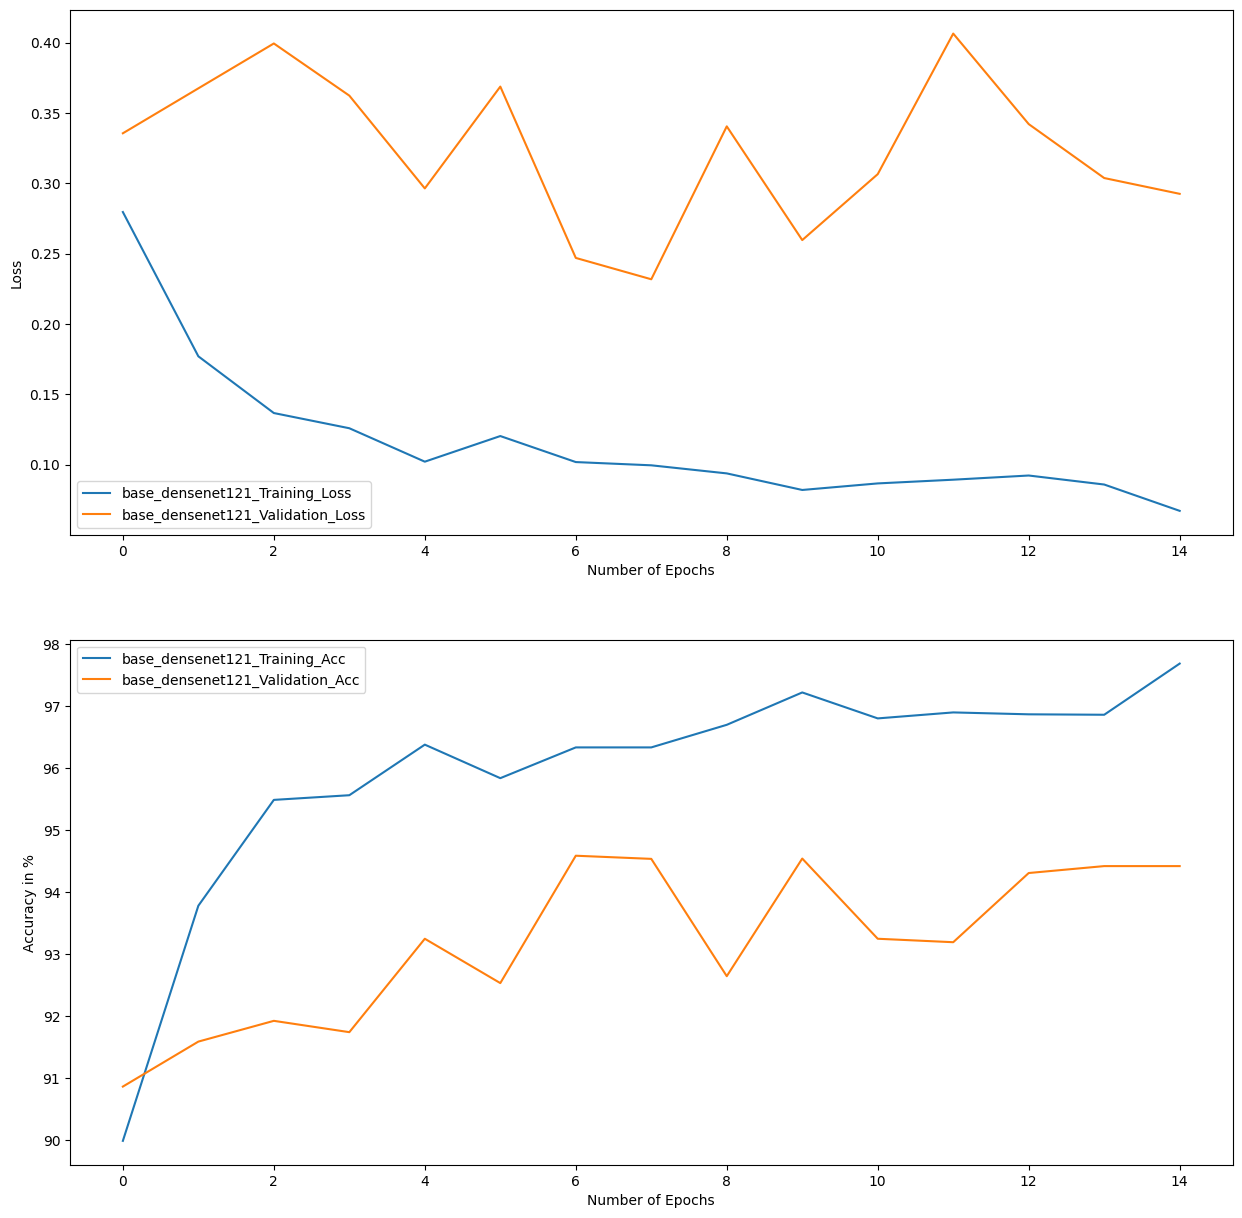

In [147]:
plot_training_statistics(history_densenet121, 'base_densenet121')

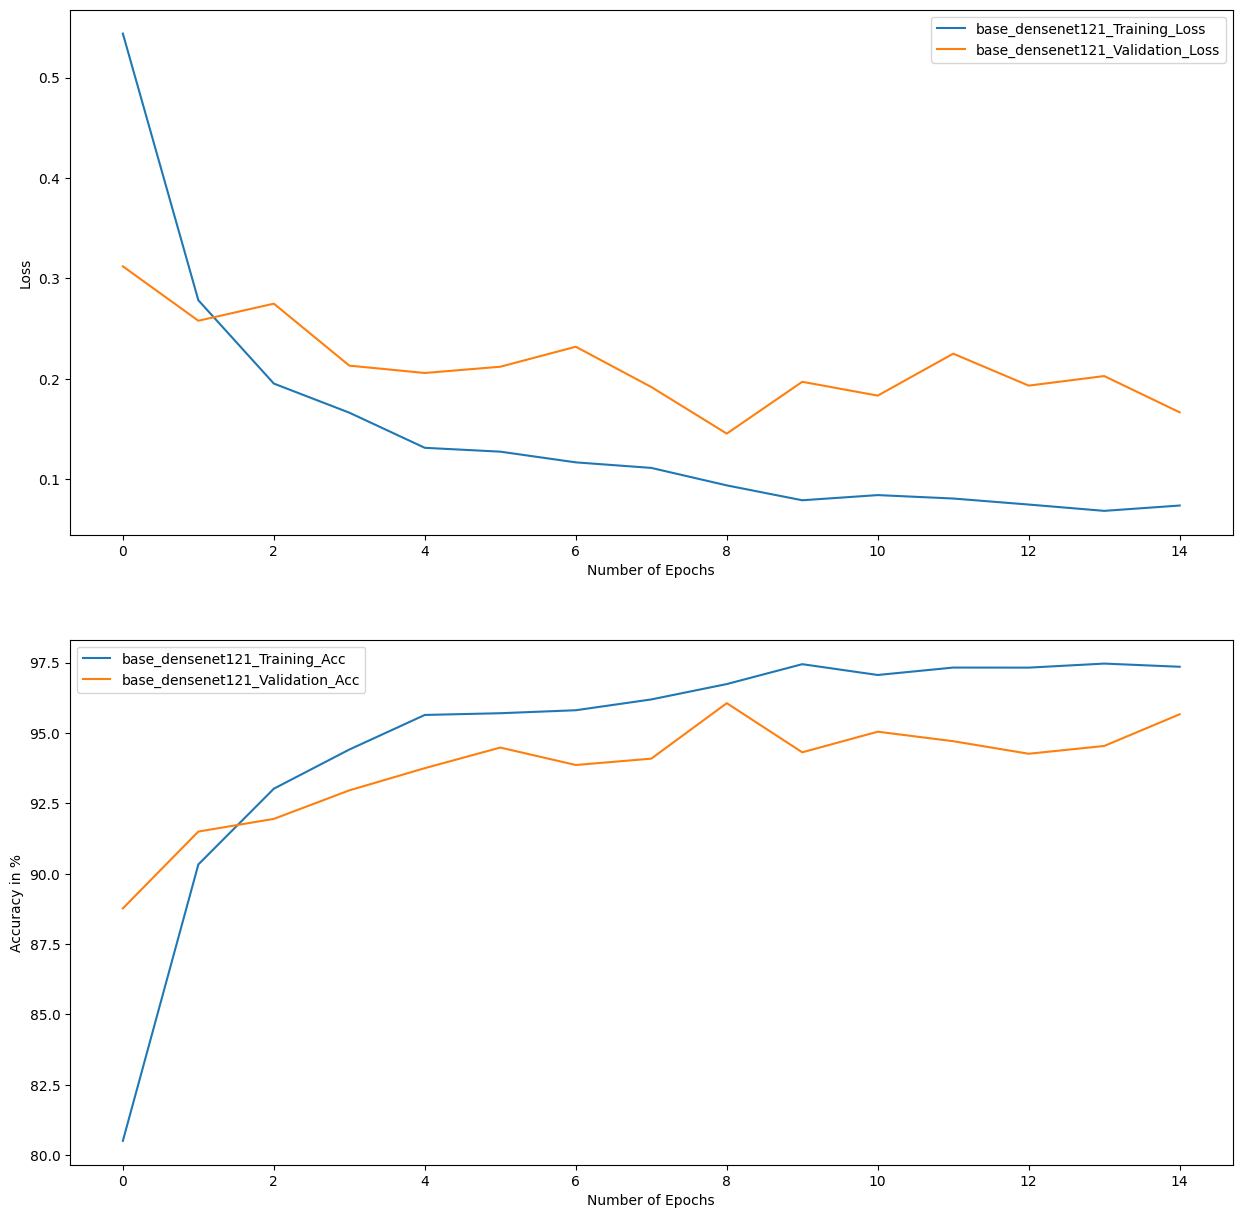

In [146]:
plot_training_statistics(history_densenet121_16_SGS, 'base_densenet121')

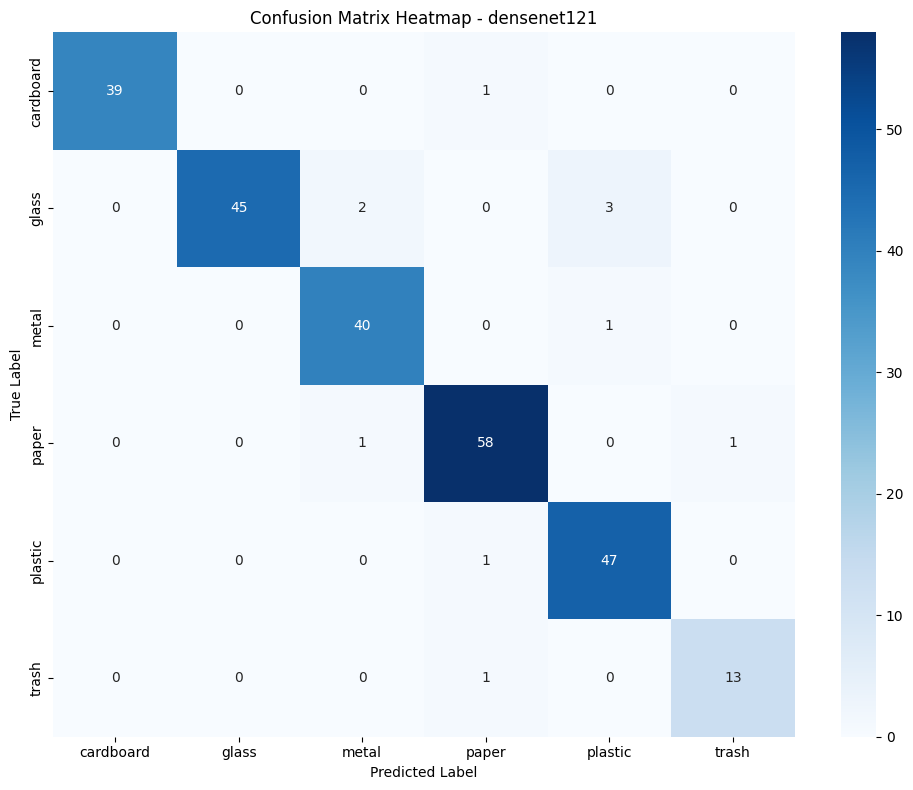

In [148]:
plot_confusion_matrix(base_densenet121, test_loader, class_names, device='cuda', model_name="densenet121")

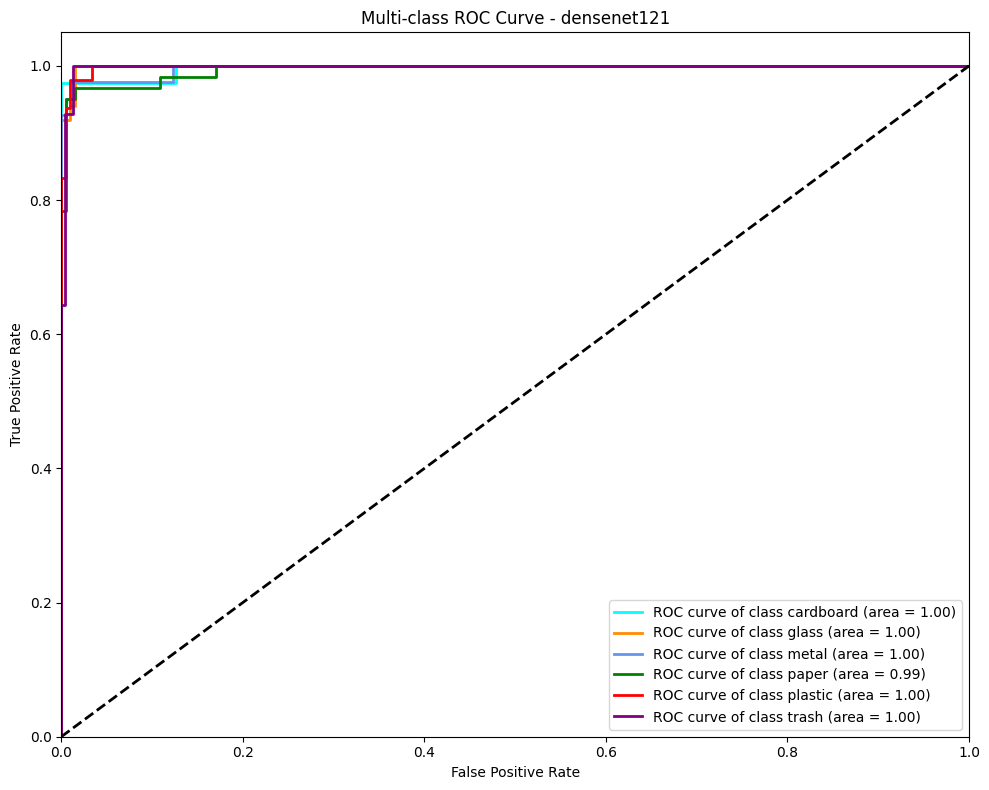

In [154]:
plot_multiclass_roc(base_densenet121, test_loader, class_names, device='cuda', model_name="densenet121")

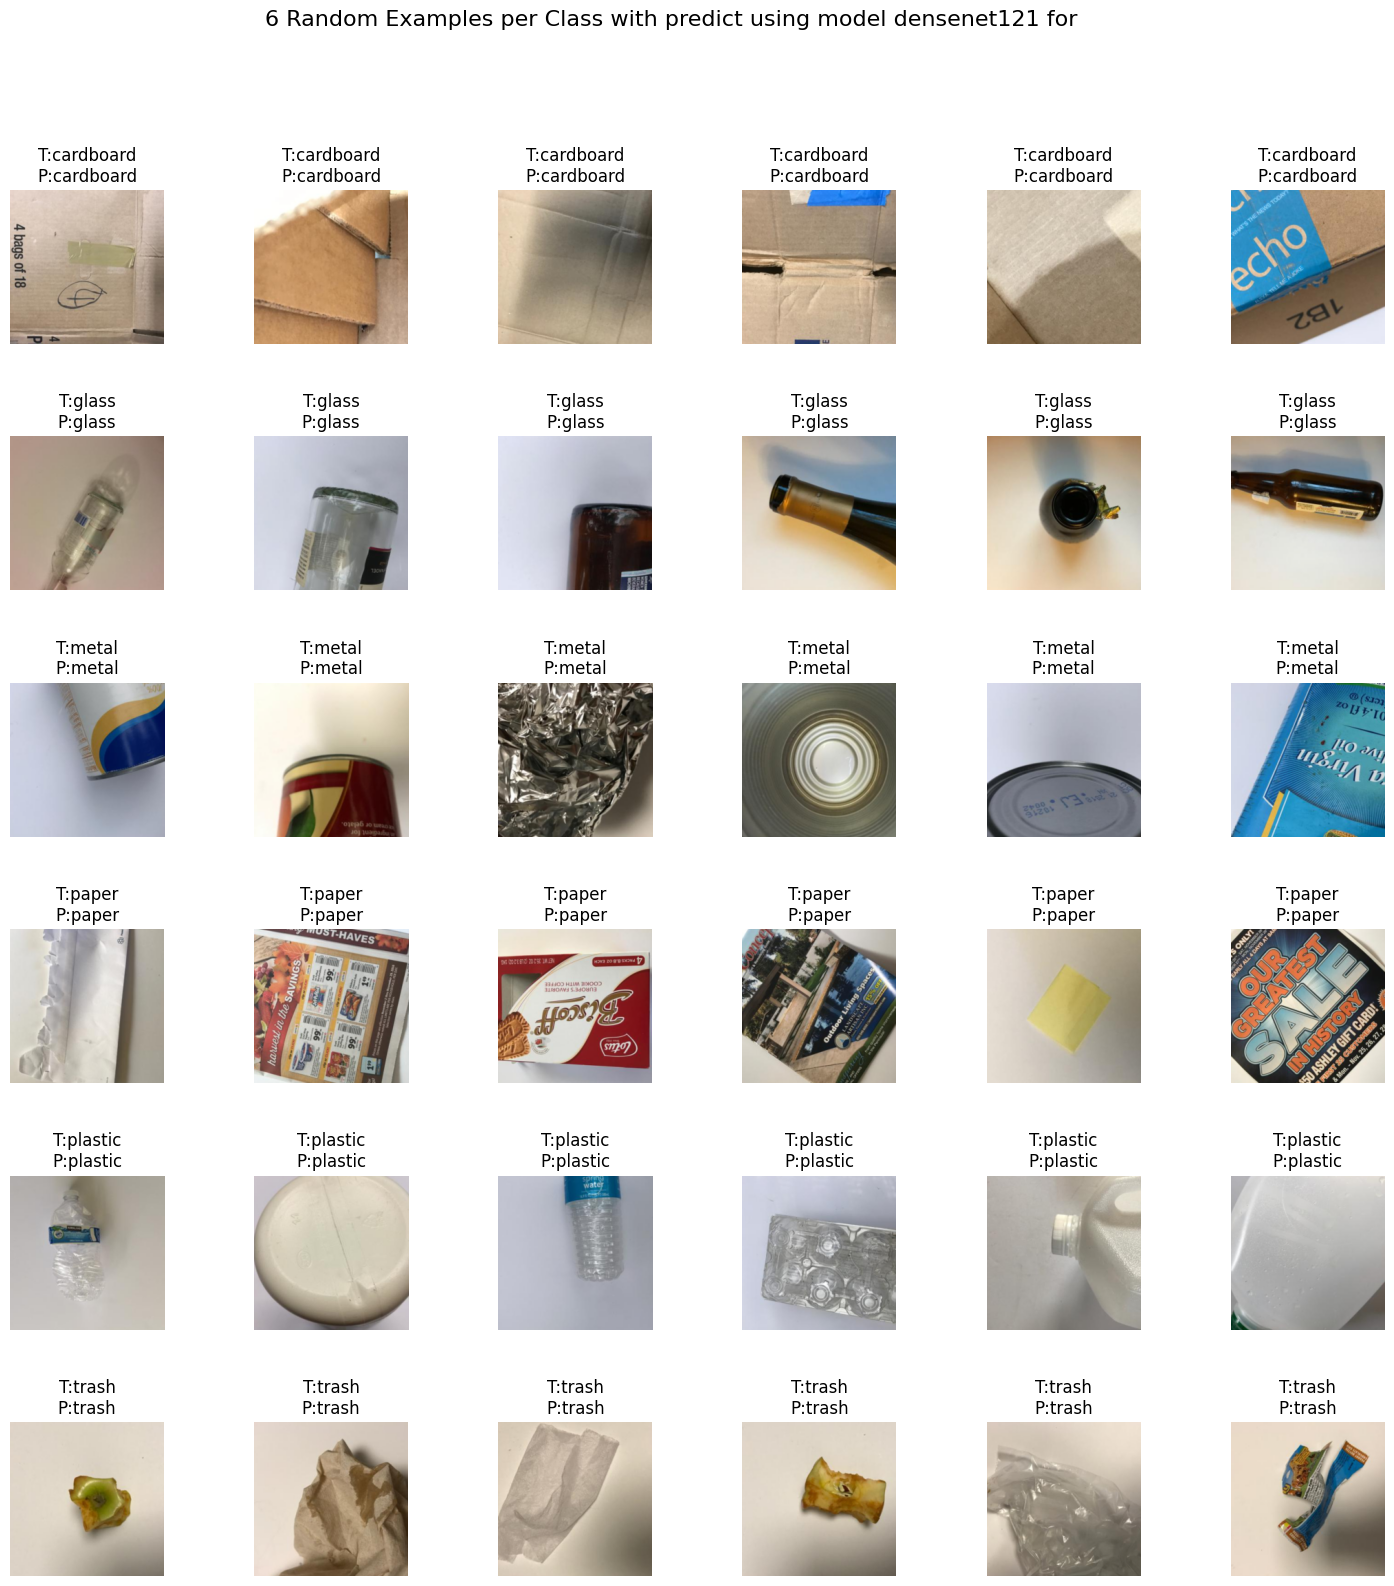

In [162]:
visualize_predictions(base_densenet121, test_dataset, classes, device='cuda',model_name='densenet121')

In [8]:
# 1) Re-instantiate your model architecture:
# same args as when you created it
base_densenet121.cuda

# 2) Load the weights:
state_dict = torch.load("/kaggle/working/Trashfolder/base_densenet121.pt", map_location=device)
model_loaded=base_densenet121.load_state_dict(state_dict)
#model.eval()                       # set to evaluation mode
print("✅ Model weights loaded and model set to eval()")

NameError: name 'base_densenet121' is not defined

In [ ]:
# Load the state_dict of our saved model (this will update the new instance of our model with trained weights)
loaded_model_0.load_state_dict(torch.load(f="/kaggle/working/Trashfolder/base_densenet121.pt"))

In [6]:
save_model(base_densenet121,"base_densenet121_15_epoches_with_train_all_wieghts_16batch_SGD.pt")

NameError: name 'base_densenet121' is not defined

## train inception_v3

In [58]:
train_loader, val_loader,test_loader, class_names, input_size=prepare_dataloaders(data_dir,data_dir_test, "inception_v3", batch_size=16)

Train samples: 14147, Batches: 885
Validation samples: 1771, Batches: 111
Test samples: 253, Batches: 16


In [59]:
print("train_loader=",train_loader)
print("val_loader=",val_loader)
print("test_loader=",test_loader)
print("class_names=",class_names)
print("input_size=",input_size)

train_loader= <torch.utils.data.dataloader.DataLoader object at 0x7d262d090350>
val_loader= <torch.utils.data.dataloader.DataLoader object at 0x7d262d1e86d0>
test_loader= <torch.utils.data.dataloader.DataLoader object at 0x7d262cee0c50>
class_names= ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
input_size= 299


In [ ]:
#Now create your optimizer over only those trainable parameters:
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, base_inception_v3.parameters()),
    lr=1e-4,  # often lower LR for fine‑tuning
)

In [ ]:
optimizer_inception_v3=optim.SGD( filter(lambda p: p.requires_grad,base_inception_v3.parameters()), lr=0.001,momentum=0.9 )

In [ ]:
#trainning
history_mobilenet_v2=fit_model(base_inception_v3 , "inception_v3", train_loader, val_loader,criterion, optimizer_inception_v3,epochs, device)

In [ ]:
evaluate_batch_predictions(
    model=base_inception_v3,
    data_loader=test_loader,
    criterion=criterion,
    device=device,
    model_name="inception_v3"
)

In [ ]:
plot_training_statistics(history_mobilenet_v2, 'inception_v3')

In [ ]:
plot_confusion_matrix(base_inception_v3, test_loader, class_names, device='cuda', model_name="inception_v3")

In [ ]:
plot_multiclass_roc(base_inception_v3, test_loader, class_names, device='cuda', model_name="inception_v3")

In [ ]:
visualize_predictions(base_inception_v3, test_loader, class_names, device='cuda', model_name='inception_v3', n_images=16)

In [ ]:
save_model(base_inception_v3,"inception_v3_15_epoches.pth")

## train Resnet50

In [60]:
train_loader, val_loader,test_loader, class_names, input_size=prepare_dataloaders(data_dir,data_dir_test, "Resnet50", batch_size=16)

Train samples: 14147, Batches: 885
Validation samples: 1771, Batches: 111
Test samples: 253, Batches: 16


In [61]:
print("train_loader=",train_loader)
print("val_loader=",val_loader)
print("test_loader=",test_loader)
print("class_names=",class_names)
print("input_size=",input_size)

train_loader= <torch.utils.data.dataloader.DataLoader object at 0x7d262d4005d0>
val_loader= <torch.utils.data.dataloader.DataLoader object at 0x7d262cfaac90>
test_loader= <torch.utils.data.dataloader.DataLoader object at 0x7d262d400610>
class_names= ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
input_size= 224


In [ ]:
#Now create your optimizer over only those trainable parameters:
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, base_resnet50.parameters()),
    lr=1e-4,  # often lower LR for fine‑tuning
)

In [ ]:
optimizer_resnet50=optim.SGD(filter(lambda p: p.requires_grad,base_resnet50.parameters()), lr=0.001,momentum=0.9 )

In [ ]:
#trainning
history_resnet50=fit_model(base_resnet50 , "resnet50", train_loader, val_loader,criterion, optimizer_resnet50,epochs, device)

In [ ]:
evaluate_batch_predictions(
    model=base_resnet50,
    data_loader=test_loader,
    criterion=criterion,
    device=device,
    model_name="resnet50"
)

In [ ]:
plot_training_statistics(history_resnet50, 'resnet50')

In [ ]:
plot_confusion_matrix(base_resnet50, test_loader, class_names, device='cuda', model_name="resnet50")

In [ ]:
plot_multiclass_roc(base_resnet50, test_loader, class_names, device='cuda', model_name="resnet50")

In [ ]:
visualize_predictions(base_resnet50, test_loader, class_names, device='cuda', model_name='resnet50', n_images=16)

In [ ]:
save_model(base_resnet50,"resnet50_15_epoches.pth")